# RQ4 Test 1: is spring greenness linked to later fire?

**Sepehr Mansouri, MSc Applied Computing, BCIT. Supervisor: Dr. Michal Aibin.**
Run dates (Google Colab): original **17 October 2026**, current **23 November 2026**. The original run covered Sections 1 to 7. The current run covers the whole notebook, including Section 8, and the outputs shown are from this run. The results of Sections 1 to 7 are identical in both runs. Section 8 was added at Dr. Aibin's request. It rebuilds F1, F3 and NDVI from earlier years only and compares the old and new AUC.

**Question.** Did 1 km cells that burned in summer (1 June to 31 October) have an unusual spring greenness (April and May) before the fire? This test looks for a link only. It does not train a forecast model (that is Test 2).

**Main result** (fire years 2019 to 2025, 361,200 cell-years, 4,740 burned):

| Measure | AUC | 95% interval |
|---|---|---|
| F1, spring greenness anomaly | 0.717 | 0.598 to 0.804 |
| F3, greenness in August and September of the year before | 0.817 | 0.732 to 0.885 |
| MODIS NDVI, spring (comparison) | 0.731 | 0.634 to 0.803 |

AUC is the chance that a random burned cell has a higher value than a random unburned cell (0.5 means no link).

**Known weaknesses** (found after this run, and the reason for Test 2): F1 compares each spring with all other years, including years after a fire, and the direction of the link and the pass rule were not agreed with my supervisor before the fire data were opened.


The monthly images, vegetation, NDVI, weather and FIRMS layers were made beforehand in Google Earth Engine (scripts `rq4_step5a_veg_mask.js`, `rq4_step5b_reference_layers.js` and the Step 4 export script) and saved to the Drive folder `rq4_s2`.

## 1. Setup and settings

Connect Google Drive, load every library used in the notebook and print the versions.

In [1]:
# Connect Google Drive (the Earth Engine exports and all results live there)
from google.colab import drive
drive.mount('/content/drive')

!pip install -q rasterio

# All libraries used in this notebook
import os, sys, re, json, hashlib, zipfile, shutil, warnings
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio, pyogrio, shapely
from shapely.geometry import box
import scipy, sklearn, statsmodels, matplotlib
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score
from scipy.stats import spearmanr

# Cells with no clear image give empty averages. These warnings are expected and hidden.
warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="invalid value encountered")
warnings.filterwarnings("ignore", category=FutureWarning)

print('Python', sys.version.split()[0])
for m in [np, pd, gpd, rasterio, scipy, sklearn, statsmodels, matplotlib]:
    print(f'{m.__name__:12s}', m.__version__)
RASTERS = '/content/drive/MyDrive/rq4_s2'
print('Raster files found:', len([f for f in os.listdir(RASTERS) if f.endswith('.tif')]) if os.path.exists(RASTERS) else 'folder not created yet')

Mounted at /content/drive
Python 3.13.18
numpy        2.4.6
pandas       2.2.3
geopandas    1.2.0
rasterio     1.5.2
scipy        1.16.3
sklearn      1.6.1
statsmodels  0.15.0
matplotlib   3.10.0
Raster files found: 119


All settings in one place: folders, the seven study squares, and the values used by each part. The squares were placed at random (seed 20261014) inside the BC Wildfire Service fire centres. The corners are checked against the table exported from Earth Engine.

In [2]:
# Folders in Google Drive
BASE_DIR   = Path("/content/drive/MyDrive")
RASTER_DIR = BASE_DIR / "rq4_s2"          # Earth Engine exports (GeoTIFF files)
NBAC_DIR   = BASE_DIR / "NBAC"            # fire data
OUT_DIR    = BASE_DIR / "rq4_outputs"     # tables and figures made by this notebook
NBAC_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

CRS = "EPSG:3005"       # BC Albers map projection (metres)
CELL_SIZE = 1000.0      # 1 km cells, 100 x 100 cells per square

# The seven study squares, corners in metres (Coastal_1 was removed on 15 Oct 2026)
SQUARES = pd.DataFrame(
    [("Prince_George_1", "Prince George Fire Centre", 1040000, 1095000, 1140000, 1195000),
     ("Prince_George_2", "Prince George Fire Centre", 1212000, 1221000, 1312000, 1321000),
     ("Kamloops_1",      "Kamloops Fire Centre",      1362000,  546000, 1462000,  646000),
     ("Kamloops_2",      "Kamloops Fire Centre",      1387000,  662000, 1487000,  762000),
     ("Cariboo_1",       "Cariboo Fire Centre",       1095000,  770000, 1195000,  870000),
     ("Southeast_1",     "Southeast Fire Centre",     1633000,  595000, 1733000,  695000),
     ("Northwest_1",     "Northwest Fire Centre",      878000,  965000,  978000, 1065000)],
    columns=["square_id", "centre", "xmin", "ymin", "xmax", "ymax"]).set_index("square_id")

# Check the corners against the table exported from Earth Engine, if it is in Drive
csv_path = BASE_DIR / "rq4_step3_selected_squares.csv"
if csv_path.exists():
    ee_sq = pd.read_csv(csv_path).set_index("square_id").drop(index="Coastal_1", errors="ignore")
    diff = (ee_sq.loc[SQUARES.index, ["xmin", "ymin", "xmax", "ymax"]] - SQUARES[["xmin", "ymin", "xmax", "ymax"]]).abs()
    assert set(ee_sq.index) == set(SQUARES.index) and float(diff.values.max()) == 0, "Squares differ from the Step 3 export"
    print("Squares match", csv_path.name)
else:
    print("Step 3 CSV not found in Drive; using the corners above (from the data log)")

# Part 3 and 4: greenness and comparison features
FIRST_YEAR, LAST_YEAR = 2019, 2026   # 2017 and 2018 have too few clear spring images
YEARS = list(range(FIRST_YEAR, LAST_YEAR + 1))
MIN_CLEAR       = 2      # clear views needed for a valid cell-month
MIN_OTHER_YEARS = 4      # other valid years needed to compute an anomaly
VEG_MIN_CELL    = 0.5    # minimum vegetated share of a cell
INDICES   = ["gcc", "rcc", "bright"]   # greenness, redness, brightness
VARIABLES = ["red", "green", "blue", "gcc", "rcc", "bright", "snow_frac", "n_clear"]

# Part 6: fire labels
OUTCOME_YEARS = list(range(2019, 2026))   # NBAC covers fire seasons up to 2025
FIRMS_YEARS   = list(range(2019, 2027))   # FIRMS also covers 2026 (not used in the main result)
OUTCOME_START = (6, 1)                    # fire season starts 1 June
OUTCOME_END   = (10, 31)                  # and ends 31 October
MIN_OVERLAP_M2 = 100.0                    # overlap needed to count (one 10 m Sentinel-2 pixel)
FIRMS_EARLY_MONTHS  = [4, 5]              # April and May: spring fires are removed
FIRMS_SEASON_MONTHS = [6, 7, 8, 9, 10]

# Part 7: statistics
ANALYSIS_YEARS = list(range(2019, 2026))
N_BOOT = 1000                             # bootstrap repeats
BOOT_SEED = 20261014
EXCLUDE = ["burned_before", "early_nbac", "early_firms", "late_nbac", "unknown_nbac", "prescribed_nbac"]
FEATURES = ["F1", "F2", "F3", "F4"]       # Sentinel-2 features (F1 is the main one)
REFS = ["z_ndvi", "z_precip", "z_t2m", "z_swvl1"]   # comparison features
DECIDING_FEATURES = ["F1", "F3"]
P_MAX = 0.05

print(SQUARES)

Squares match rq4_step3_selected_squares.csv
                                    centre     xmin     ymin     xmax     ymax
square_id                                                                     
Prince_George_1  Prince George Fire Centre  1040000  1095000  1140000  1195000
Prince_George_2  Prince George Fire Centre  1212000  1221000  1312000  1321000
Kamloops_1            Kamloops Fire Centre  1362000   546000  1462000   646000
Kamloops_2            Kamloops Fire Centre  1387000   662000  1487000   762000
Cariboo_1              Cariboo Fire Centre  1095000   770000  1195000   870000
Southeast_1          Southeast Fire Centre  1633000   595000  1733000   695000
Northwest_1          Northwest Fire Centre   878000   965000   978000  1065000


## 2. Fire data download (NBAC)

The National Burned Area Composite (NBAC) maps the outline and start date of every fire in Canada from 1972 to 2025. This cell only downloads it and records its SHA-256 fingerprint, which shows exactly which version was used.

In [3]:
URL = 'https://cwfis.cfs.nrcan.gc.ca/downloads/nbac/'
FILES = ['NBAC_1972to2025_20260513_shp.zip',
         'NBAC_1972to2025_20260513_shp_metadata.pdf']
for f in FILES:
    !wget -c -q --show-progress -P "{NBAC_DIR}" "{URL}{f}"

!ls -l "{NBAC_DIR}"
!sha256sum "{NBAC_DIR}"/*

total 3203838
-rw------- 1 root root    3483845 May 22  2026 NBAC_1972to2025_20260513_shp_metadata.pdf
-rw------- 1 root root 1257052370 May 22  2026 NBAC_1972to2025_20260513_shp.zip
-rw------- 1 root root       1038 Oct 17 20:16 nbac_download_record.json
-rw------- 1 root root          5 Oct 17 20:15 NBAC_merged_1972_to_2025_20260513.cpg
-rw------- 1 root root  139785412 Oct 17 20:15 NBAC_merged_1972_to_2025_20260513.dbf
-rw------- 1 root root    3483845 Oct 17 20:15 NBAC_merged_1972_to_2025_20260513.pdf
-rw------- 1 root root        478 Oct 17 20:15 NBAC_merged_1972_to_2025_20260513.prj
-rw------- 1 root root     506396 Oct 17 20:15 NBAC_merged_1972_to_2025_20260513.sbn
-rw------- 1 root root      22228 Oct 17 20:15 NBAC_merged_1972_to_2025_20260513.sbx
-rw------- 1 root root 1875927468 Oct 17 20:16 NBAC_merged_1972_to_2025_20260513.shp
-rw------- 1 root root      41929 Oct 17 20:16 NBAC_merged_1972_to_2025_20260513.shp.xml
-rw------- 1 root root     420980 Oct 17 20:15 NBAC_merged_1

Check that the zip file is not damaged and compute its fingerprint.

In [4]:
ZIP_NAME = "NBAC_1972to2025_20260513_shp.zip"
NBAC_URL = URL + ZIP_NAME
zip_path = NBAC_DIR / ZIP_NAME
if not zip_path.exists():
    raise FileNotFoundError(f"{zip_path} not found. Run the download cell first.")
print("Using zip:", zip_path, f"({zip_path.stat().st_size / 1e9:.2f} GB)")

# testzip() reads every file in the zip and returns the first damaged one, or None
with zipfile.ZipFile(zip_path) as z:
    bad = z.testzip()
    members = [(i.filename, i.file_size) for i in z.infolist()]
if bad is not None:
    raise RuntimeError(f"Damaged file inside the zip: {bad}. Download the zip again.")
print("Zip check passed. Files inside:")
for name, size in members:
    print(f"  {name:55s} {size / 1e6:10,.1f} MB")

sha = hashlib.sha256()
with open(zip_path, "rb") as f:
    for block in iter(lambda: f.read(16 * 1024 * 1024), b""):
        sha.update(block)
zip_sha256 = sha.hexdigest()
print("\nSHA-256 of the zip:", zip_sha256)

Using zip: /content/drive/MyDrive/NBAC/NBAC_1972to2025_20260513_shp.zip (1.26 GB)
Zip check passed. Files inside:
  NBAC_merged_1972_to_2025_20260513.shx                          0.4 MB
  NBAC_merged_1972_to_2025_20260513.cpg                          0.0 MB
  NBAC_merged_1972_to_2025_20260513.dbf                        139.8 MB
  NBAC_merged_1972_to_2025_20260513.pdf                          3.5 MB
  NBAC_merged_1972_to_2025_20260513.prj                          0.0 MB
  NBAC_merged_1972_to_2025_20260513.sbn                          0.5 MB
  NBAC_merged_1972_to_2025_20260513.sbx                          0.0 MB
  NBAC_merged_1972_to_2025_20260513.shp                      1,875.9 MB
  NBAC_merged_1972_to_2025_20260513.shp.xml                      0.0 MB

SHA-256 of the zip: c42740eb9d2fe3991a27344d0c33927705ec3e78c277efc5311b502439cb2165


Unzip the files into the same Drive folder. Files that are already complete are skipped, which means the cell can be run again if it stops.

In [5]:
with zipfile.ZipFile(zip_path) as z:
    for info in z.infolist():
        if info.is_dir():
            continue
        target = NBAC_DIR / Path(info.filename).name
        if target.exists() and target.stat().st_size == info.file_size:
            print(f"Already complete, skipped: {target.name}")
            continue
        tmp = target.with_name(target.name + ".part")       # write to a temporary name first
        with z.open(info) as src, open(tmp, "wb") as dst:
            shutil.copyfileobj(src, dst, length=16 * 1024 * 1024)
        tmp.replace(target)
        print(f"Extracted: {target.name} ({info.file_size / 1e6:,.1f} MB)")

# Final check: every file is present with the right size
missing = [n for n, s in members
           if not (NBAC_DIR / Path(n).name).exists()
           or (NBAC_DIR / Path(n).name).stat().st_size != s]
print("\nAll files complete." if not missing else f"\nINCOMPLETE: {missing}")

Already complete, skipped: NBAC_merged_1972_to_2025_20260513.shx
Already complete, skipped: NBAC_merged_1972_to_2025_20260513.cpg
Already complete, skipped: NBAC_merged_1972_to_2025_20260513.dbf
Already complete, skipped: NBAC_merged_1972_to_2025_20260513.pdf
Already complete, skipped: NBAC_merged_1972_to_2025_20260513.prj
Already complete, skipped: NBAC_merged_1972_to_2025_20260513.sbn
Already complete, skipped: NBAC_merged_1972_to_2025_20260513.sbx
Already complete, skipped: NBAC_merged_1972_to_2025_20260513.shp
Already complete, skipped: NBAC_merged_1972_to_2025_20260513.shp.xml

All files complete.


Save a record of the download for the data log.

In [6]:
record = {
    "dataset": "National Burned Area Composite (NBAC), 1972 to 2025, release 20260513",
    "source_url": NBAC_URL,
    "zip_file": zip_path.name,
    "zip_size_bytes": zip_path.stat().st_size,
    "zip_sha256": zip_sha256,
    "files": dict(members),
    "extracted_to": str(NBAC_DIR),
    "recorded_at": datetime.now().isoformat(timespec="seconds"),
    "note": "Downloaded and extracted only. Fire records not opened before the pre-registration memo.",
}
with open(NBAC_DIR / "nbac_download_record.json", "w") as f:
    json.dump(record, f, indent=2)
print(json.dumps({k: v for k, v in record.items() if k != "files"}, indent=2))

{
  "dataset": "National Burned Area Composite (NBAC), 1972 to 2025, release 20260513",
  "source_url": "https://cwfis.cfs.nrcan.gc.ca/downloads/nbac/NBAC_1972to2025_20260513_shp.zip",
  "zip_file": "NBAC_1972to2025_20260513_shp.zip",
  "zip_size_bytes": 1257052370,
  "zip_sha256": "c42740eb9d2fe3991a27344d0c33927705ec3e78c277efc5311b502439cb2165",
  "extracted_to": "/content/drive/MyDrive/NBAC",
  "recorded_at": "2026-11-23T16:44:07",
  "note": "Downloaded and extracted only. Fire records not opened before the pre-registration memo."
}


## 3. Greenness features from Sentinel-2 (no fire data)

**Input.** One GeoTIFF per square and year (`rq4_s2_<square>_<year>.tif`) with one band per variable and month, for example `gcc_2023_05`. Each band is a 1 km monthly median of the cloud-free Sentinel-2 Level-2A views. Plus `rq4_veg_<square>.tif`, the vegetated share of each cell (ESA WorldCover).

**Definitions**
- A cell-month is **valid** if it had at least `MIN_CLEAR` (2) clear views.
- **Anomaly** of a cell in month m of year y: z = (value in year y − mean of the other years) / standard deviation of the other years. It needs at least `MIN_OTHER_YEARS` (4) other valid years.
- **F1**: mean of the April and May greenness anomalies (both needed).
- **F2**: the same for brightness (R + G + B).
- **F3**: mean of the August and September greenness anomalies of the year before.
- **F4**: trend of June to August greenness over the three previous years, (value in y−1 − value in y−3) / 2.
- Cells less than half vegetated keep a row but get no feature values.

First, find the files and check that each one is on the expected grid.

In [7]:
def check_grid(path, sq):
    """Stop if a raster is not 100 x 100 cells of 1 km in EPSG:3005 with the square's corner."""
    with rasterio.open(path) as r:
        t = r.transform
        problems = []
        if r.crs is None or r.crs.to_epsg() != 3005: problems.append(f"CRS {r.crs}")
        if (r.width, r.height) != (100, 100):      problems.append(f"size {r.width}x{r.height}")
        if not np.isclose(t.a, CELL_SIZE) or not np.isclose(t.e, -CELL_SIZE): problems.append("cell size")
        if not np.isclose(t.c, SQUARES.at[sq, "xmin"]) or not np.isclose(t.f, SQUARES.at[sq, "ymax"]):
            problems.append(f"corner {t.c},{t.f} vs {SQUARES.at[sq,'xmin']},{SQUARES.at[sq,'ymax']}")
    if problems:
        raise ValueError(f"{path.name}: " + "; ".join(problems))

print("Squares:", list(SQUARES.index))

# Find the Sentinel-2 files: rq4_s2_<square>_<year>.tif
pattern = re.compile(r"^rq4_s2_(.+)_(\d{4})\.tif$")
files = {}
for p in sorted(RASTER_DIR.glob("rq4_s2_*_*.tif")):
    m = pattern.match(p.name)
    if not m:
        continue
    sq, yr = m.group(1), int(m.group(2))
    if sq not in SQUARES.index:
        print("Skipped (not a study square):", p.name)
        continue
    if FIRST_YEAR <= yr <= LAST_YEAR:
        files[(sq, yr)] = p

for (sq, yr), p in files.items():
    check_grid(p, sq)
expected = [(sq, y) for sq in SQUARES.index for y in YEARS]
missing = [k for k in expected if k not in files]
print(f"Raster files found and checked: {len(files)} of {len(expected)} expected")
if missing:
    print("Missing (square, year):", missing)

# Vegetation files
veg_files = {sq: RASTER_DIR / f"rq4_veg_{sq}.tif" for sq in SQUARES.index}
veg_missing = [sq for sq, p in veg_files.items() if not p.exists()]
if veg_missing:
    raise FileNotFoundError("Vegetation files missing for: " + ", ".join(veg_missing))
for sq, p in veg_files.items():
    check_grid(p, sq)
print("Vegetation files found and checked:", len(veg_files))

Squares: ['Prince_George_1', 'Prince_George_2', 'Kamloops_1', 'Kamloops_2', 'Cariboo_1', 'Southeast_1', 'Northwest_1']
Raster files found and checked: 56 of 56 expected
Vegetation files found and checked: 7


Load every file into one array per square with the shape (year, month, variable, row, column), and count the valid cells in each month. The table shows the number of valid cells (of 10,000) per square, year and month.

In [8]:
yi = {y: i for i, y in enumerate(YEARS)}          # year -> position in the array
vi = {v: i for i, v in enumerate(VARIABLES)}      # variable -> position in the array
band_re = re.compile(r"^(.+)_(\d{4})_(\d{2})$")   # band names such as gcc_2023_05

data, veg = {}, {}
inventory = []
for sq in SQUARES.index:
    arr = np.full((len(YEARS), 12, len(VARIABLES), 100, 100), np.nan, dtype=np.float32)
    for y in YEARS:
        p = files.get((sq, y))
        if p is None:
            continue
        with rasterio.open(p) as r:
            for b, desc in enumerate(r.descriptions, start=1):
                m = band_re.match(desc or "")
                if not m or m.group(1) not in vi or int(m.group(2)) != y:
                    continue
                a = r.read(b).astype(np.float32)
                if r.nodata is not None:
                    a[a == r.nodata] = np.nan
                arr[yi[y], int(m.group(3)) - 1, vi[m.group(1)]] = a
    data[sq] = arr
    with rasterio.open(veg_files[sq]) as r:
        veg[sq] = r.read(1).astype(np.float32)

    # Coverage of each month
    for y in YEARS:
        for mth in range(12):
            g = arr[yi[y], mth, vi["gcc"]]
            n = arr[yi[y], mth, vi["n_clear"]]
            inventory.append({"square_id": sq, "year": y, "month": mth + 1,
                              "file_found": (sq, y) in files,
                              "cells_with_gcc": int(np.isfinite(g).sum()),
                              "cells_valid": int((np.isfinite(g) & (n >= MIN_CLEAR)).sum()),
                              "median_gcc": float(np.nanmedian(g)) if np.isfinite(g).any() else np.nan,
                              "median_n_clear": float(np.nanmedian(n)) if np.isfinite(n).any() else np.nan})

inventory = pd.DataFrame(inventory)
inventory.to_csv(OUT_DIR / "rq4_step5_inventory.csv", index=False)
print("Vegetated cells (fraction >= VEG_MIN_CELL) per square:")
for sq in SQUARES.index:
    print(f"  {sq:16s} {int((veg[sq] >= VEG_MIN_CELL).sum()):6d} of 10000")
inventory.pivot_table(index=["square_id", "year"], columns="month", values="cells_valid").astype("Int64")

Vegetated cells (fraction >= VEG_MIN_CELL) per square:
  Prince_George_1    9640 of 10000
  Prince_George_2    9742 of 10000
  Kamloops_1         9791 of 10000
  Kamloops_2         9547 of 10000
  Cariboo_1          9897 of 10000
  Southeast_1        7780 of 10000
  Northwest_1        8547 of 10000


month                    1      2      3      4      5      6      7      8   \
square_id       year                                                           
Cariboo_1       2019   9901  10000  10000   9469   9999   8271   5363   8991   
                2020   9643  10000  10000   9966   9998   5753   8506   9980   
                2021   9999   9998   9975   9995   8346   9961  10000   8139   
                2022   6779  10000  10000   8303   6645   8389   9943  10000   
                2023   9943   9999  10000   9857  10000   9970   9766   9999   
                2024   8931   9994  10000   9240   4962   7236   9977   9052   
                2025   9982  10000   8636   9904   8854   8194   9227   9991   
                2026   9190   9657   9989  10000  10000   8883  10000  10000   
Kamloops_1      2019   9090   6606  10000   7816   9789   9281   8255   9497   
                2020   7296   9203   9263   9939   8582   7730   9643   9974   
                2021   8602   8269   9949   9751   9163   9961  10000   9993   
                2022   9269   9912   9211   9670   6875   9289  10000  10000   
                2023   9724   8148  10000   9988  10000   9496  10000   9800   
                2024   5513   9289  10000   9073   9041   9610  10000  10000   
                2025   9379   9543   9817   9977   9387   9997   9677   9998   
                2026   9906   9883   8386   9988   8397   8705   9940  10000   
Kamloops_2      2019   9122   9969  10000   9840   9983   8424   9787   9736   
                2020   7572   8658  10000   9954   9573   7440   9993   9999   
                2021   8133   9625   9910  10000   9917  10000  10000   9974   
                2022   8158   9988   9993   9720   7504   9859  10000  10000   
                2023   8790   5774  10000  10000  10000   9962   9968  10000   
                2024   9019   9861  10000   9995   9887   9960  10000   9900   
                2025   7479   9955   9891  10000   9974  10000   9947  10000   
                2026   9457   8992   7277   9998   8308   9227   9992   9976   
Northwest_1     2019   9243  10000  10000   9997   9980   8292   8810   9959   
                2020   8921   9734  10000   9999   9988   7266   9032    701   
                2021   6371   9590   9685  10000   9436   9613   9999  10000   
                2022   9257   9170   9010   9667   9398   9515   9985   9683   
                2023   8353   9154  10000   9998  10000  10000   9984  10000   
                2024   9715   9853  10000   9659   7527   8658   9956   9983   
                2025   9719  10000   9548   9589   6002   9960   9394  10000   
                2026   9820   8984   9243  10000   9467   9916  10000  10000   
Prince_George_1 2019   8038   9952  10000   9837  10000   7433   9203   9810   
                2020  10000   9940   9993  10000   9999   4982   7530   8799   
                2021   9684   9997   9236  10000   7973   9559   9886   9421   
                2022   8431   9362   9636   9998   8471   9072   9204   9986   
                2023   7448   8049  10000   7768   9655   9266   9586   9973   
                2024   8795   9796  10000  10000   8544   7125   9975  10000   
                2025   9309  10000   9995   9995   9334   9935   9148  10000   
                2026   9861   9998  10000   9986  10000   9505   9997  10000   
Prince_George_2 2019  10000  10000  10000  10000  10000   8342   9965   9867   
                2020   9955  10000  10000  10000   9678   8362   9900   9980   
                2021  10000  10000  10000   9947   9186   9994   9994   9972   
                2022  10000   9974  10000   9786   9393   9983  10000  10000   
                2023   9828  10000  10000  10000  10000   9962   9985  10000   
                2024   9835  10000  10000  10000   9980   9718  10000  10000   
                2025   9862  10000   9963  10000  10000   9897   9970  10000   
                2026   9956   9819  10000  10000  10000   9967  10000  10000   


Compute the anomalies. For each cell and month, every year is compared with the **other** years of the same cell. The function uses running sums, which gives the mean and standard deviation of the other years without a loop over years.

In [9]:
def loyo(x, valid):
    """Leave-one-year-out anomaly.
    x, valid: arrays (years, rows, cols). Returns z, diff (= value minus mean of other years) and the number of other years."""
    xv = np.where(valid, x, 0.0).astype(np.float64)
    n  = valid.sum(axis=0)                 # valid years per cell
    S  = xv.sum(axis=0)                    # sum over all valid years
    SS = (xv ** 2).sum(axis=0)             # sum of squares
    n_other = n[None] - valid              # remove the target year itself
    S_o  = S[None]  - xv
    SS_o = SS[None] - xv ** 2
    with np.errstate(invalid="ignore", divide="ignore"):
        mean_o = S_o / n_other
        var_o  = (SS_o - n_other * mean_o ** 2) / (n_other - 1)
        sd_o   = np.sqrt(np.clip(var_o, 0, None))
        ok   = valid & (n_other >= MIN_OTHER_YEARS)
        diff = np.where(ok, x - mean_o, np.nan)
        z    = np.where(ok & (sd_o > 0), diff / sd_o, np.nan)
    return z.astype(np.float32), diff.astype(np.float32), n_other.astype(np.int16)

anom = {}
for sq, arr in data.items():
    nclear = arr[:, :, vi["n_clear"]]
    valid_all = np.isfinite(nclear) & (nclear >= MIN_CLEAR)
    anom[sq] = {}
    for idx in INDICES:
        z = np.full(arr.shape[:2] + (100, 100), np.nan, np.float32)
        d = np.full_like(z, np.nan)
        no = np.zeros(z.shape, np.int16)
        for mth in range(12):
            x = arr[:, mth, vi[idx]]
            v = valid_all[:, mth] & np.isfinite(x)
            z[:, mth], d[:, mth], no[:, mth] = loyo(x, v)
        anom[sq][idx] = {"z": z, "diff": d, "n_other": no}
print("Anomalies computed for", len(anom), "squares and indices", INDICES)

Anomalies computed for 7 squares and indices ['gcc', 'rcc', 'bright']


Save one row per cell, year and month (raw values and anomalies) for later checks.

In [10]:
rows_idx, cols_idx = np.meshgrid(np.arange(100), np.arange(100), indexing="ij")
frames = []
for sq, arr in data.items():
    x0, y0 = SQUARES.at[sq, "xmin"], SQUARES.at[sq, "ymax"]
    cx = (x0 + (cols_idx + 0.5) * CELL_SIZE).ravel()      # cell centre, x
    cy = (y0 - (rows_idx + 0.5) * CELL_SIZE).ravel()      # cell centre, y
    for y in YEARS:
        for mth in range(12):
            rec = {"square_id": sq, "year": y, "month": mth + 1,
                   "row": rows_idx.ravel().astype(np.int16), "col": cols_idx.ravel().astype(np.int16),
                   "cell_x": cx, "cell_y": cy,
                   "veg_frac": veg[sq].ravel(), "veg_ok": (veg[sq] >= VEG_MIN_CELL).ravel()}
            for v in VARIABLES:
                rec[v] = arr[yi[y], mth, vi[v]].ravel()
            rec["valid"] = (np.isfinite(rec["n_clear"]) & (rec["n_clear"] >= MIN_CLEAR))
            for idx in INDICES:
                rec[f"z_{idx}"]      = anom[sq][idx]["z"][yi[y], mth].ravel()
                rec[f"diff_{idx}"]   = anom[sq][idx]["diff"][yi[y], mth].ravel()
                rec[f"nother_{idx}"] = anom[sq][idx]["n_other"][yi[y], mth].ravel()
            frames.append(pd.DataFrame(rec))
cell_month = pd.concat(frames, ignore_index=True)
cell_month["square_id"] = cell_month["square_id"].astype("category")
cell_month.to_parquet(OUT_DIR / "rq4_cell_month.parquet", index=False)
print(f"rq4_cell_month.parquet: {len(cell_month):,} rows, {cell_month.shape[1]} columns")

rq4_cell_month.parquet: 6,720,000 rows, 27 columns


Build the four features F1 to F4 for every cell and year. The table shows how many cells have each feature.

In [11]:
def both_mean(a, b):
    """Mean of two months, only where both months have a value."""
    return np.where(np.isfinite(a) & np.isfinite(b), (a + b) / 2.0, np.nan)

frames = []
for sq, arr in data.items():
    zg = anom[sq]["gcc"]["z"]          # greenness anomalies
    zb = anom[sq]["bright"]["z"]       # brightness anomalies
    gcc = arr[:, :, vi["gcc"]]
    nclear = arr[:, :, vi["n_clear"]]
    gcc_valid = np.where(np.isfinite(nclear) & (nclear >= MIN_CLEAR), gcc, np.nan)
    # June to August mean greenness, only where all three months are valid (used for F4)
    jja = np.where(np.isfinite(gcc_valid[:, 5:8]).all(axis=1), np.nanmean(gcc_valid[:, 5:8], axis=1), np.nan)
    vok = veg[sq] >= VEG_MIN_CELL
    x0, y0 = SQUARES.at[sq, "xmin"], SQUARES.at[sq, "ymax"]
    for y in YEARS:
        i = yi[y]
        F1 = both_mean(zg[i, 3], zg[i, 4])                     # April and May (months 4 and 5)
        F2 = both_mean(zb[i, 3], zb[i, 4])
        F3 = both_mean(zg[i - 1, 7], zg[i - 1, 8]) if i >= 1 else np.full((100, 100), np.nan)   # Aug and Sep, year before
        if i >= 3:
            all3 = np.isfinite(jja[i - 1]) & np.isfinite(jja[i - 2]) & np.isfinite(jja[i - 3])
            F4 = np.where(all3, (jja[i - 1] - jja[i - 3]) / 2.0, np.nan)
        else:
            F4 = np.full((100, 100), np.nan)
        feats = {"F1": F1, "F2": F2, "F3": F3, "F4": F4}
        rec = {"square_id": sq, "year": y,
               "row": rows_idx.ravel().astype(np.int16), "col": cols_idx.ravel().astype(np.int16),
               "cell_x": (x0 + (cols_idx + 0.5) * CELL_SIZE).ravel(),
               "cell_y": (y0 - (rows_idx + 0.5) * CELL_SIZE).ravel(),
               "veg_frac": veg[sq].ravel(), "veg_ok": vok.ravel()}
        for k, v in feats.items():
            rec[k] = np.where(vok, v, np.nan).ravel().astype(np.float32)   # no values for low-vegetation cells
        frames.append(pd.DataFrame(rec))

features = pd.concat(frames, ignore_index=True)
features["square_id"] = features["square_id"].astype("category")
features.to_parquet(OUT_DIR / "rq4_cell_year_features.parquet", index=False)

coverage = (features.groupby(["square_id", "year"], observed=True)[["F1", "F2", "F3", "F4"]]
            .apply(lambda g: g.notna().sum()).reset_index())
coverage.to_csv(OUT_DIR / "rq4_step5_feature_coverage.csv", index=False)
print("Cells with each feature (vegetated cells only), per square and year:")
coverage

Cells with each feature (vegetated cells only), per square and year:


,square_id,year,F1,F2,F3,F4
0,Cariboo_1,2019,8965,8965,0,0
1,Cariboo_1,2020,9360,9360,8500,0
2,Cariboo_1,2021,8254,8254,9789,0
3,Cariboo_1,2022,6370,6370,7354,3960
4,Cariboo_1,2023,9284,9284,9863,5212
5,Cariboo_1,2024,4888,4888,9020,7250
6,Cariboo_1,2025,8693,8693,8956,6472
7,Cariboo_1,2026,9390,9390,9791,6267
8,Kamloops_1,2019,7445,7445,0,0
9,Kamloops_1,2020,8148,8148,8360,0


A quick check that the images behave like plant growth: the median greenness of vegetated cells in each month, one line per year. Greenness should rise in spring and fall in autumn.

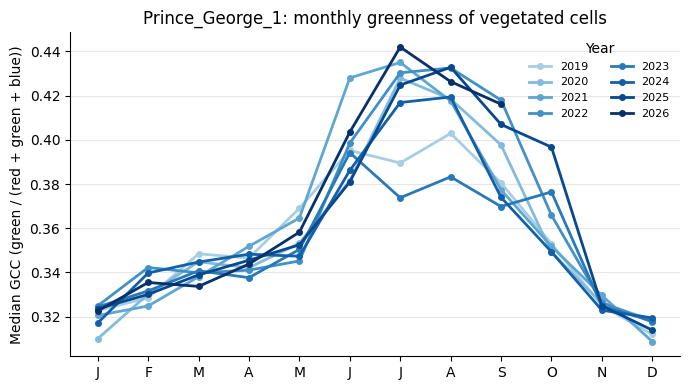

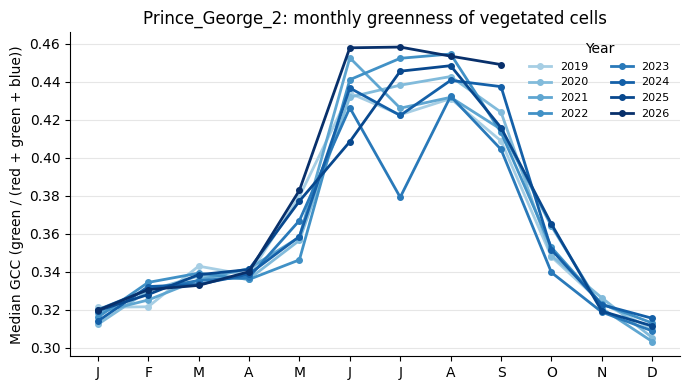

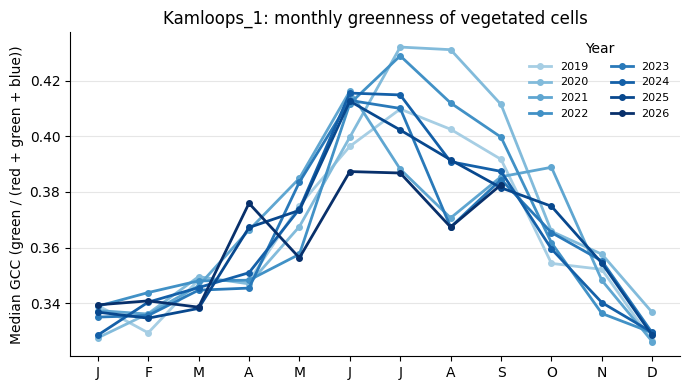

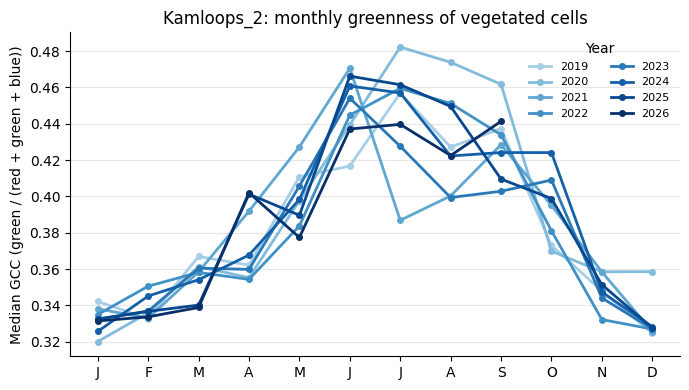

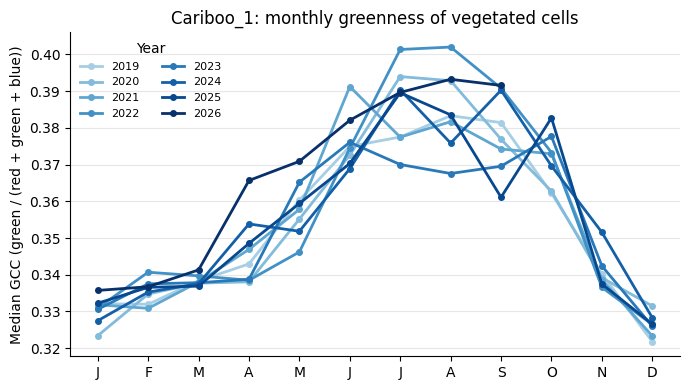

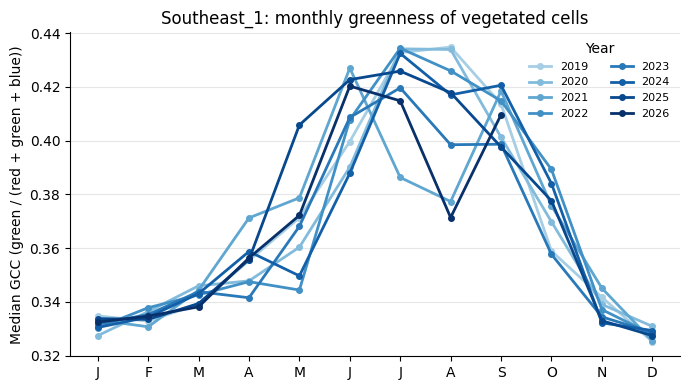

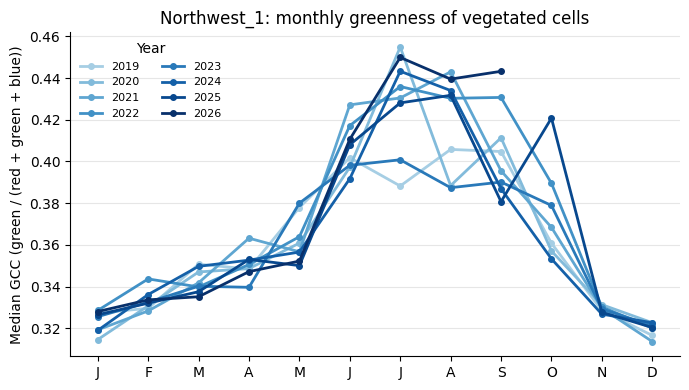

In [12]:
month_labels = ["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]
cmap = matplotlib.colormaps["Blues"]
shades = [cmap(0.35 + 0.65 * k / max(1, len(YEARS) - 1)) for k in range(len(YEARS))]

for sq, arr in data.items():
    vok = veg[sq] >= VEG_MIN_CELL
    fig, ax = plt.subplots(figsize=(7, 4))
    for k, y in enumerate(YEARS):
        g = arr[yi[y], :, vi["gcc"]]
        n = arr[yi[y], :, vi["n_clear"]]
        g = np.where((n >= MIN_CLEAR) & vok[None], g, np.nan)
        med = [np.nanmedian(g[m]) if np.isfinite(g[m]).any() else np.nan for m in range(12)]
        if np.isfinite(med).any():
            ax.plot(range(1, 13), med, color=shades[k], lw=2, marker="o", ms=4, label=str(y))
    ax.set_xticks(range(1, 13), month_labels)
    ax.set_ylabel("Median GCC (green / (red + green + blue))")
    ax.set_title(f"{sq}: monthly greenness of vegetated cells")
    ax.grid(axis="y", color="0.9")
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.legend(title="Year", frameon=False, ncol=2, fontsize=8)
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"fig_seasonal_gcc_{sq}.png", dpi=150)
    plt.show()

Save the settings used in this part.

In [13]:
settings = {
    "run_at": datetime.now().isoformat(timespec="seconds"),
    "FIRST_YEAR": FIRST_YEAR, "LAST_YEAR": LAST_YEAR,
    "MIN_CLEAR": MIN_CLEAR, "MIN_OTHER_YEARS": MIN_OTHER_YEARS, "VEG_MIN_CELL": VEG_MIN_CELL,
    "INDICES": INDICES,
    "raster_files": sorted(p.name for p in files.values()),
    "missing_square_years": [list(k) for k in missing],
    "versions": {"numpy": np.__version__, "pandas": pd.__version__, "rasterio": rasterio.__version__},
    "fire_data_used": False,
}
with open(OUT_DIR / "rq4_step5_settings.json", "w") as f:
    json.dump(settings, f, indent=2)
print("Saved to", OUT_DIR)

Saved to /content/drive/MyDrive/rq4_outputs


## 4. Comparison features: MODIS NDVI and ERA5-Land weather (no fire data)

These are inputs a forecast would already have. They are built with the same anomaly rule, which makes them directly comparable with the RGB features.

- `z_ndvi`: mean of the April and May NDVI anomalies (MODIS, Normalized Difference Vegetation Index)
- `z_precip`: anomaly of the March to May total precipitation (ERA5-Land)
- `z_t2m`: anomaly of the March to May mean air temperature (ERA5-Land)
- `z_swvl1`: anomaly of the May topsoil moisture (ERA5-Land)

First, read the NDVI and ERA5-Land files. The table shows the share of cells with an April NDVI value.

In [14]:
def read_monthly(path, variables):
    """Read bands named <variable>_YYYY_MM into {variable: array (years, 12, 100, 100)}."""
    out = {v: np.full((len(YEARS), 12, 100, 100), np.nan, np.float32) for v in variables}
    with rasterio.open(path) as r:
        for b, desc in enumerate(r.descriptions, start=1):
            m = band_re.match(desc or "")
            if not m or m.group(1) not in out or int(m.group(2)) not in yi:
                continue
            a = r.read(b).astype(np.float32)
            if r.nodata is not None:
                a[a == r.nodata] = np.nan
            out[m.group(1)][yi[int(m.group(2))], int(m.group(3)) - 1] = a
    return out

ref = {}
for sq in SQUARES.index:
    paths = {"ndvi": RASTER_DIR / f"rq4_ndvi_{sq}.tif", "era5": RASTER_DIR / f"rq4_era5_{sq}.tif"}
    missing = [k for k, p in paths.items() if not p.exists()]
    if missing:
        raise FileNotFoundError(f"{sq}: missing " + ", ".join(str(paths[k].name) for k in missing))
    for p in paths.values():
        check_grid(p, sq)
    ref[sq] = {**read_monthly(paths["ndvi"], ["ndvi"]),
               **read_monthly(paths["era5"], ["t2m", "precip", "swvl1"])}
print("Files found and checked for", len(ref), "squares")

# Share of cells with a value (April NDVI shown)
cov = []
for sq, d in ref.items():
    for y in YEARS:
        cov.append({"square_id": sq, "year": y,
                    "ndvi_apr": float(np.isfinite(d["ndvi"][yi[y], 3]).mean()),
                    "ndvi_may": float(np.isfinite(d["ndvi"][yi[y], 4]).mean()),
                    "precip_may": float(np.isfinite(d["precip"][yi[y], 4]).mean()),
                    "t2m_may": float(np.isfinite(d["t2m"][yi[y], 4]).mean())})
pd.DataFrame(cov).pivot_table(index="square_id", columns="year", values="ndvi_apr").round(2)

Files found and checked for 7 squares


year,2019,2020,2021,2022,2023,2024,2025,2026
square_id,,,,,,,,
Cariboo_1,1.00,1.00,0.95,0.87,0.99,0.99,0.99,1.00
Kamloops_1,0.99,0.91,0.92,0.92,0.96,0.99,0.99,1.00
Kamloops_2,0.87,0.76,0.80,0.71,0.84,0.86,0.89,0.91
Northwest_1,0.75,0.69,0.57,0.50,0.61,0.70,0.75,0.68
Prince_George_1,0.67,0.52,0.48,0.44,0.62,0.83,0.80,0.65
Prince_George_2,1.00,1.00,0.99,0.98,0.99,1.00,1.00,0.99
Southeast_1,0.58,0.46,0.54,0.43,0.57,0.55,0.63,0.59


Compute the four comparison features and save them. The table shows how many cells have each one.

In [15]:
def all_months(arr, months):
    """Select some months of arr (years, 12, r, c) and flag cells where all of them have a value."""
    sub = arr[:, [m - 1 for m in months]]
    return sub, np.isfinite(sub).all(axis=1)

frames = []
for sq, d in ref.items():
    # NDVI: anomaly of each month, then the mean of April and May
    z_nd = np.full((len(YEARS), 12, 100, 100), np.nan, np.float32)
    for mth in range(12):
        x = d["ndvi"][:, mth]
        z_nd[:, mth], _, _ = loyo(x, np.isfinite(x))
    z_ndvi = both_mean(z_nd[:, 3], z_nd[:, 4])

    # Weather: first the spring total or mean, then its anomaly
    pr, pr_ok = all_months(d["precip"], [3, 4, 5]);  precip_mam = np.where(pr_ok, pr.sum(axis=1), np.nan)
    tt, tt_ok = all_months(d["t2m"],    [3, 4, 5]);  t2m_mam    = np.where(tt_ok, tt.mean(axis=1), np.nan)
    swvl1_may = d["swvl1"][:, 4]
    z_precip, _, _ = loyo(precip_mam, np.isfinite(precip_mam))
    z_t2m,    _, _ = loyo(t2m_mam,    np.isfinite(t2m_mam))
    z_swvl1,  _, _ = loyo(swvl1_may,  np.isfinite(swvl1_may))

    vok = veg[sq] >= VEG_MIN_CELL
    for y in YEARS:
        i = yi[y]
        rec = {"square_id": sq, "year": y,
               "row": rows_idx.ravel().astype(np.int16), "col": cols_idx.ravel().astype(np.int16)}
        for k, v in {"z_ndvi": z_ndvi, "z_precip": z_precip, "z_t2m": z_t2m, "z_swvl1": z_swvl1}.items():
            rec[k] = np.where(vok, v[i], np.nan).ravel().astype(np.float32)
        frames.append(pd.DataFrame(rec))

reference = pd.concat(frames, ignore_index=True)
reference["square_id"] = reference["square_id"].astype("category")
reference.to_parquet(OUT_DIR / "rq4_cell_year_reference.parquet", index=False)
print(f"rq4_cell_year_reference.parquet: {len(reference):,} rows")
(reference.groupby(["square_id", "year"], observed=True)[["z_ndvi", "z_precip", "z_t2m", "z_swvl1"]]
 .apply(lambda g: g.notna().sum()))

rq4_cell_year_reference.parquet: 560,000 rows


z_ndvi  z_precip  z_t2m  z_swvl1
square_id       year                                  
Cariboo_1       2019    9814      9897   9897     9897
                2020    9821      9897   9897     9897
                2021    9413      9897   9897     9897
                2022    8644      9897   9897     9897
                2023    9789      9897   9897     9897
                2024    9764      9897   9897     9897
                2025    9813      9897   9897     9897
                2026    9821      9897   9897     9897
Kamloops_1      2019    9529      9791   9791     9791
                2020    8865      9791   9791     9791
                2021    8964      9791   9791     9791
                2022    9006      9791   9791     9791
                2023    9394      9791   9791     9791
                2024    9532      9791   9791     9791
                2025    9555      9791   9791     9791
                2026    9559      9791   9791     9791
Kamloops_2      2019    7838      9547   9547     9547
                2020    7089      9547   9547     9547
                2021    7552      9547   9547     9547
                2022    6554      9547   9547     9547
                2023    7684      9547   9547     9547
                2024    7782      9547   9547     9547
                2025    7863      9547   9547     9547
                2026    7904      9547   9547     9547
Northwest_1     2019    6172      8547   8547     8547
                2020    6019      8547   8547     8547
                2021    5180      8547   8547     8547
                2022    4715      8547   8547     8547
                2023    5745      8547   8547     8547
                2024    6150      8547   8547     8547
                2025    6190      8547   8547     8547
                2026    6003      8547   8547     8547
Prince_George_1 2019    5474      9640   9640     9640
                2020    4662      9640   9640     9640
                2021    4454      9640   9640     9640
                2022    4105      9640   9640     9640
                2023    5330      9640   9640     9640
                2024    5709      9640   9640     9640
                2025    5630      9640   9640     9640
                2026    5184      9640   9640     9640
Prince_George_2 2019    9710      9742   9742     9742
                2020    9729      9742   9742     9742
                2021    9710      9742   9742     9742
                2022    9622      9742   9742     9742
                2023    9700      9742   9742     9742
                2024    9732      9742   9742     9742
                2025    9732      9742   9742     9742
                2026    9682      9742   9742     9742
Southeast_1     2019    5015      7780   7780     7780
                2020    4287      7780   7780     7780
                2021    4843      7780   7780     7780
                2022    3893      7780   7780     7780
                2023    4959      7780   7780     7780
                2024    4890      7780   7780     7780
                2025    5056      7780   7780     7780
                2026    5032      7780   7780     7780

Save the settings used in this part.

In [16]:
settings = {
    "run_at": datetime.now().isoformat(timespec="seconds"),
    "FIRST_YEAR": FIRST_YEAR, "LAST_YEAR": LAST_YEAR,
    "MIN_OTHER_YEARS": MIN_OTHER_YEARS, "VEG_MIN_CELL": VEG_MIN_CELL,
    "definitions": {"z_ndvi": "mean of April and May LOYO z of MOD13A3 NDVI (QA 0 or 1)",
                    "z_precip": "LOYO z of March to May total precipitation (ERA5-Land)",
                    "z_t2m": "LOYO z of March to May mean 2 m temperature (ERA5-Land)",
                    "z_swvl1": "LOYO z of May volumetric soil water layer 1 (ERA5-Land)"},
    "versions": {"numpy": np.__version__, "pandas": pd.__version__, "rasterio": rasterio.__version__},
    "fire_data_used": False,
}
with open(OUT_DIR / "rq4_step5c_settings.json", "w") as f:
    json.dump(settings, f, indent=2)
print("Saved to", OUT_DIR)

Saved to /content/drive/MyDrive/rq4_outputs


## 5. Extreme-value check (no fire data)

When a cell's standard deviation over the other years is very small, its anomaly can become very large. This cell shows how often that happens. It matters for the logistic regression, not for the AUC, which only uses the ranking of values. In the run, this cell was run before the fire data were opened.

In [17]:
feat = pd.read_parquet(OUT_DIR / "rq4_cell_year_features.parquet")
refs = pd.read_parquet(OUT_DIR / "rq4_cell_year_reference.parquet")
YRS = list(range(2019, 2026))                      # fire years with NBAC
feat = feat[feat.year.isin(YRS)]
refs = refs[refs.year.isin(YRS)]

rows = []
for name, df in [("F1", feat), ("F2", feat), ("F3", feat), ("F4", feat),
                 ("z_ndvi", refs), ("z_precip", refs), ("z_t2m", refs), ("z_swvl1", refs)]:
    v = df[name].to_numpy(dtype=float)
    v = v[np.isfinite(v)]
    a = np.abs(v)
    rows.append({"feature": name, "n": len(v), "min": v.min(), "p1": np.percentile(v, 1),
                 "median": np.median(v), "p99": np.percentile(v, 99), "max": v.max(),
                 "share_abs_gt3": (a > 3).mean(), "share_abs_gt5": (a > 5).mean(),
                 "share_abs_gt10": (a > 10).mean(), "count_abs_gt100": int((a > 100).sum())})
tab = pd.DataFrame(rows).set_index("feature")
# F4 is a slope in gcc units per year, not a z value: the threshold columns do not apply
tab.loc["F4", ["share_abs_gt3", "share_abs_gt5", "share_abs_gt10", "count_abs_gt100"]] = np.nan
tab.to_csv(OUT_DIR / "rq4_step5_extremes.csv")

by_square = (feat.assign(abs_F1=feat.F1.abs())
             .groupby("square_id", observed=True)
             .agg(n=("F1", "count"),
                  share_abs_gt3=("abs_F1", lambda s: (s > 3).sum() / s.notna().sum()),
                  max_abs=("abs_F1", "max")))
by_square.to_csv(OUT_DIR / "rq4_step5_extremes_F1_by_square.csv")

pd.set_option("display.float_format", lambda x: f"{x:,.4g}")   # shorter numbers in all later tables
print("Distribution of each feature, outcome years 2019 to 2025, vegetated cells")
display(tab)
print("F1 by square")
display(by_square)
print("Saved rq4_step5_extremes.csv and rq4_step5_extremes_F1_by_square.csv in", OUT_DIR)

Distribution of each feature, outcome years 2019 to 2025, vegetated cells


,n,min,p1,median,p99,max,share_abs_gt3,share_abs_gt5,share_abs_gt10,count_abs_gt100
feature,,,,,,,,,,
F1,394063,-23.6,-2.211,-0.09564,2.931,22.78,0.0119,0.001726,0.0001294,0
F2,394063,-13.99,-2.019,-0.02575,4.553,41.27,0.02904,0.008133,0.001137,0
F3,350682,-18.06,-2.856,-0.03285,2.664,14.32,0.01402,0.001161,3.137e-05,0
F4,171361,-0.08312,-0.03354,-0.003433,0.02096,0.04443,NaN,NaN,NaN,NaN
z_ndvi,360678,-25.24,-2.799,-0.09272,2.362,12.5,0.01139,0.001267,5.822e-05,0
z_precip,454608,-3.878,-2.56,-0.1798,2.625,4.053,0.00516,0,0,0
z_t2m,454608,-4.023,-3.201,0.1499,2.959,4.134,0.02481,0,0,0
z_swvl1,454608,-9.245,-3.779,0.1168,3.072,4.507,0.03531,0.003627,0,0


F1 by square


,n,share_abs_gt3,max_abs
square_id,,,
Cariboo_1,55814,0.00808,19.38
Kamloops_1,56833,0.009273,15.78
Kamloops_2,63452,0.007218,12.63
Northwest_1,52215,0.00791,23.6
Prince_George_1,59502,0.01766,17.32
Prince_George_2,66310,0.009818,13.77
Southeast_1,39937,0.02847,22.78


Saved rq4_step5_extremes.csv and rq4_step5_extremes_F1_by_square.csv in /content/drive/MyDrive/rq4_outputs


## 6. Fire labels and removals (reads fire data)

**Definitions**
- Fire **start date** = the earlier of `HS_SDATE` (first satellite hotspot) and `AG_SDATE` (agency start date).
- Each fire of year y gets one class: `prescribed` (planned burn), `unknown` (no start date), `early` (before 1 June), `late` (after 31 October) or `outcome` (inside the season). Only `outcome` fires count as burning.
- `burned`: outcome fires cover more than 100 m² of the cell.
- Cell-years removed later: burned in any earlier year since 1972 (`burned_before`), touched by an early, late, unknown or prescribed fire of the same year, or a FIRMS fire detection in April or May (`early_firms`).

**Note on the date in the next cell.** The section was set to run only once a date was entered for the agreed rules. In this run the field held "2026-10-21", which I entered on 17 October and which does not belong to any agreed note. The value does not change any result. The rules were not agreed with my supervisor before this run.

The next cell copies the 1.9 GB shapefile to the Colab disk, which makes reading it much faster.

In [18]:
PREREG_MEMO_DATE = "2026-10-21"   # see the note above
if not PREREG_MEMO_DATE:
    raise RuntimeError("Fill in PREREG_MEMO_DATE first. This section reads fire data.")
print("Pre-registration memo dated", PREREG_MEMO_DATE)

# Copy the shapefile files to the Colab disk (skipped if already copied this session)
NBAC_STEM = "NBAC_merged_1972_to_2025_20260513"
LOCAL_NBAC = Path("/content/nbac_local")
LOCAL_NBAC.mkdir(exist_ok=True)
for p in NBAC_DIR.glob(NBAC_STEM + ".*"):
    if p.suffix == ".part":
        continue
    q = LOCAL_NBAC / p.name
    if not q.exists() or q.stat().st_size != p.stat().st_size:
        shutil.copy2(p, q)
NBAC_SHP = LOCAL_NBAC / (NBAC_STEM + ".shp")
if not NBAC_SHP.exists():
    raise FileNotFoundError(f"{NBAC_STEM}.shp not found in {NBAC_DIR}. Run the unzip cell first.")
print("NBAC shapefile ready:", NBAC_SHP)

Pre-registration memo dated 2026-10-21
NBAC shapefile ready: /content/nbac_local/NBAC_merged_1972_to_2025_20260513.shp


Read only the fires near the seven squares and convert them to the BC Albers projection.

In [19]:
print("geopandas", gpd.__version__, "| pyogrio", pyogrio.__version__, "| shapely", shapely.__version__)
sq_boxes = gpd.GeoSeries([box(r.xmin, r.ymin, r.xmax, r.ymax) for r in SQUARES.itertuples()],
                         index=SQUARES.index, crs=CRS)

info = pyogrio.read_info(NBAC_SHP)
print("NBAC features in file:", info["features"], "| CRS:", info["crs"][:60], "...")
needed = ["YEAR", "HS_SDATE", "AG_SDATE", "PRESCRIBED", "NFIREID", "POLY_HA"]
absent = [f for f in needed if f not in list(info["fields"])]
if absent:
    raise KeyError(f"Fields not found in NBAC: {absent}. Fields present: {list(info['fields'])}")

# Read only fires inside a box around the squares (with a 5 km margin)
bbox_file_crs = tuple(gpd.GeoSeries([sq_boxes.union_all().buffer(5000)], crs=CRS)
                      .to_crs(info["crs"]).total_bounds)
fires = gpd.read_file(NBAC_SHP, bbox=bbox_file_crs, columns=needed, engine="pyogrio")
fires = fires.to_crs(CRS)
fires["geometry"] = shapely.make_valid(fires.geometry.values)     # repair broken outlines
fires = fires[fires.intersects(sq_boxes.union_all())].copy()
fires["YEAR"] = fires["YEAR"].astype(int)
print("NBAC fires overlapping the squares:", len(fires))

geopandas 1.2.0 | pyogrio 0.13.0 | shapely 2.2.0
NBAC features in file: 52610 | CRS: PROJCS["Canada_Lambert_Conformal_Conic",GEOGCS["NAD83",DATUM ...
NBAC fires overlapping the squares: 1482


Put each fire into one class from its start date. The table counts the fires of each class per year.

In [20]:
print("Values of PRESCRIBED:", fires["PRESCRIBED"].fillna("<empty>").value_counts().to_dict())
PRESCRIBED_TRUE = {"true", "t", "yes", "y", "1"}
is_prescribed = fires["PRESCRIBED"].fillna("").astype(str).str.strip().str.lower().isin(PRESCRIBED_TRUE)

# Start date = the earlier of the hotspot date and the agency date
hs = pd.to_datetime(fires["HS_SDATE"], errors="coerce")
ag = pd.to_datetime(fires["AG_SDATE"], errors="coerce")
fires["start"] = pd.concat([hs, ag], axis=1).min(axis=1)

win_start = pd.to_datetime(fires["YEAR"].astype(str) + f"-{OUTCOME_START[0]:02d}-{OUTCOME_START[1]:02d}")
win_end   = pd.to_datetime(fires["YEAR"].astype(str) + f"-{OUTCOME_END[0]:02d}-{OUTCOME_END[1]:02d}")
cls = np.select([is_prescribed, fires["start"].isna(), fires["start"] < win_start, fires["start"] > win_end],
                ["prescribed", "unknown", "early", "late"], default="outcome")
fires["fire_class"] = cls

class_table = (fires[fires.YEAR.isin(OUTCOME_YEARS)]
               .pivot_table(index="YEAR", columns="fire_class", values="NFIREID", aggfunc="count", fill_value=0))
class_table

Values of PRESCRIBED: {'<empty>': 1469, 'true': 13}


fire_class,early,outcome,prescribed
YEAR,,,
2019,10,11,1
2020,9,13,0
2021,21,56,0
2022,17,55,0
2023,32,83,0
2024,11,52,0
2025,17,27,0


Overlay the fires with the 1 km cells of each square. For every cell and year this gives the burned label, the removal flags and the year the cell first burned. The table shows the burned cells per square and year.

In [21]:
def square_grid(sq):
    """The 100 x 100 cells of one square as polygons, with their row and column."""
    r = SQUARES.loc[sq]
    rows, cols = np.meshgrid(np.arange(100), np.arange(100), indexing="ij")
    rows, cols = rows.ravel(), cols.ravel()
    x0 = r.xmin + cols * CELL_SIZE
    y1 = r.ymax - rows * CELL_SIZE
    return gpd.GeoDataFrame({"row": rows.astype(np.int16), "col": cols.astype(np.int16)},
                            geometry=shapely.box(x0, y1 - CELL_SIZE, x0 + CELL_SIZE, y1), crs=CRS)

def area_by_cell(grid, polys):
    """Area (m2) of the fire polygons inside each cell, indexed by (row, col)."""
    if len(polys) == 0:
        return pd.Series(dtype=float)
    u = gpd.GeoDataFrame(geometry=[polys.union_all()], crs=CRS)
    inter = gpd.overlay(grid, u, how="intersection", keep_geom_type=True)
    if len(inter) == 0:
        return pd.Series(dtype=float)
    return inter.assign(a=inter.area).groupby(["row", "col"])["a"].sum()

def read_firms(sq):
    """FIRMS fire detections per month: {(year, month): array 100 x 100}."""
    p = RASTER_DIR / f"rq4_firms_{sq}.tif"
    check_grid(p, sq)
    out = {}
    with rasterio.open(p) as r:
        for b, desc in enumerate(r.descriptions, start=1):
            m = re.match(r"^firms_(\d{4})_(\d{2})$", desc or "")
            if m:
                out[(int(m.group(1)), int(m.group(2)))] = r.read(b).astype(np.float32)
    return out

frames, region_rows = [], []
for sq in SQUARES.index:
    grid = square_grid(sq)
    key = pd.MultiIndex.from_arrays([grid.row, grid.col])
    f_sq = fires[fires.intersects(sq_boxes[sq])]

    # First year each cell burned (any class), from the full record back to 1972
    first_year = pd.Series(np.nan, index=key)
    for y, g in f_sq.groupby("YEAR"):
        a = area_by_cell(grid, g)
        hit = a[a > MIN_OVERLAP_M2].index
        first_year.loc[hit] = np.fmin(first_year.loc[hit].values, y)

    firms = read_firms(sq)
    for y in sorted(set(OUTCOME_YEARS) | set(FIRMS_YEARS)):
        rec = pd.DataFrame({"square_id": sq, "year": y, "row": grid.row.values, "col": grid.col.values})
        fy = f_sq[f_sq.YEAR == y]
        for c in ["outcome", "early", "late", "unknown", "prescribed"]:
            a = area_by_cell(grid, fy[fy.fire_class == c]).reindex(key, fill_value=0.0).values
            if c == "outcome":
                rec["burn_frac"] = np.clip(a / CELL_SIZE ** 2, 0, 1)
                rec["burned"] = a > MIN_OVERLAP_M2
            else:
                rec[f"{c}_nbac"] = a > MIN_OVERLAP_M2
        rec["nbac_year_available"] = y in OUTCOME_YEARS
        rec["first_burn_year"] = first_year.values
        rec["burned_before"] = first_year.values < y
        # FIRMS: any detection in April or May removes the cell-year
        early = sum(firms.get((y, m), np.zeros((100, 100), np.float32)) for m in FIRMS_EARLY_MONTHS)
        season = sum(firms.get((y, m), np.zeros((100, 100), np.float32)) for m in FIRMS_SEASON_MONTHS)
        have_early = all((y, m) in firms for m in FIRMS_EARLY_MONTHS)
        have_season = all((y, m) in firms for m in FIRMS_SEASON_MONTHS)
        rec["early_firms"] = (np.nan_to_num(early) > 0).ravel() if have_early else False
        rec["firms_season"] = np.nan_to_num(season).ravel() if have_season else np.nan
        frames.append(rec)

        if y in OUTCOME_YEARS:
            out_fires = fy[fy.fire_class == "outcome"]
            ha_in = out_fires.intersection(sq_boxes[sq]).area.sum() / 1e4 if len(out_fires) else 0.0
            region_rows.append({"square_id": sq, "year": y, "n_outcome_fires": len(out_fires),
                                "outcome_ha_in_square": ha_in,
                                "burned_cells": int(rec["burned"].sum())})
    print(f"{sq}: done")

outcomes = pd.concat(frames, ignore_index=True)
outcomes.loc[~outcomes.nbac_year_available, ["burn_frac"]] = np.nan     # 2026 has no NBAC yet
outcomes.loc[~outcomes.nbac_year_available, ["burned"]] = False
outcomes.to_parquet(OUT_DIR / "rq4_cell_year_outcomes.parquet", index=False)
region_year = pd.DataFrame(region_rows)
region_year.to_csv(OUT_DIR / "rq4_region_year_outcomes.csv", index=False)
print(f"rq4_cell_year_outcomes.parquet: {len(outcomes):,} rows")
region_year.pivot_table(index="square_id", columns="year", values="burned_cells")

Prince_George_1: done
Prince_George_2: done
Kamloops_1: done
Kamloops_2: done
Cariboo_1: done
Southeast_1: done
Northwest_1: done
rq4_cell_year_outcomes.parquet: 560,000 rows


year,2019,2020,2021,2022,2023,2024,2025
square_id,,,,,,,
Cariboo_1,0,0,24,10,84,6,260
Kamloops_1,10,6,"1,292",21,296,11,17
Kamloops_2,1,5,430,32,648,65,7
Northwest_1,2,1,5,1,153,147,24
Prince_George_1,0,0,167,11,529,19,3
Prince_George_2,2,0,0,286,8,1,4
Southeast_1,2,119,68,77,247,411,13


How many cells burned and how many are flagged by each removal rule, per year (all seven squares, 70,000 cells per year).

In [22]:
o = outcomes[outcomes.nbac_year_available]
summary = o.groupby("year").agg(
    cells=("burned", "size"),
    burned=("burned", "sum"),
    burned_before=("burned_before", "sum"),
    early_nbac=("early_nbac", "sum"),
    early_firms=("early_firms", "sum"),
    late_nbac=("late_nbac", "sum"),
    unknown_nbac=("unknown_nbac", "sum"),
    prescribed_nbac=("prescribed_nbac", "sum"))
summary

,cells,burned,burned_before,early_nbac,early_firms,late_nbac,unknown_nbac,prescribed_nbac
year,,,,,,,,
2019,70000,17,11268,36,426,0,0,2
2020,70000,131,11305,26,185,0,0,0
2021,70000,1986,11449,68,465,0,0,0
2022,70000,438,13269,30,144,0,0,0
2023,70000,1965,13691,608,1266,0,0,0
2024,70000,660,15816,28,143,0,0,0
2025,70000,328,16359,38,256,0,0,0


Save a record of this part.

In [23]:
record = {
    "run_at": datetime.now().isoformat(timespec="seconds"),
    "prereg_memo_date": PREREG_MEMO_DATE,
    "nbac_file": NBAC_SHP.name,
    "nbac_fields_used": needed,
    "prescribed_values_seen": fires["PRESCRIBED"].fillna("<empty>").value_counts().to_dict(),
    "fires_overlapping_squares": int(len(fires)),
    "fire_class_counts_by_year": {int(k): {c: int(v) for c, v in row.items()} for k, row in class_table.iterrows()},
    "settings": {"OUTCOME_YEARS": OUTCOME_YEARS, "FIRMS_YEARS": FIRMS_YEARS,
                 "OUTCOME_START": OUTCOME_START, "OUTCOME_END": OUTCOME_END,
                 "MIN_OVERLAP_M2": MIN_OVERLAP_M2, "FIRMS_EARLY_MONTHS": FIRMS_EARLY_MONTHS,
                 "FIRMS_SEASON_MONTHS": FIRMS_SEASON_MONTHS},
    "exclusion_summary": summary.reset_index().to_dict(orient="records"),
    "versions": {"geopandas": gpd.__version__, "pyogrio": pyogrio.__version__, "shapely": shapely.__version__},
}
with open(OUT_DIR / "rq4_step6_record.json", "w") as f:
    json.dump(record, f, indent=2, default=str)
print("Saved to", OUT_DIR)

Saved to /content/drive/MyDrive/rq4_outputs


## 7. Statistics

Join the features, the comparison features and the fire labels into one table, then remove the cell-years that fail a rule: less than half vegetated, burned before, or touched by a spring, late, undated or prescribed fire. `F1_raw` is F1 without dividing by the standard deviation.

In [24]:
warnings.filterwarnings("ignore", category=RuntimeWarning)
keys = ["square_id", "year", "row", "col"]
feat = pd.read_parquet(OUT_DIR / "rq4_cell_year_features.parquet")
refs = pd.read_parquet(OUT_DIR / "rq4_cell_year_reference.parquet")
outc = pd.read_parquet(OUT_DIR / "rq4_cell_year_outcomes.parquet")
for d in (feat, refs, outc):
    d["square_id"] = d["square_id"].astype(str)

# F1_raw: mean of the April and May greenness differences (both months needed)
cm = pd.read_parquet(OUT_DIR / "rq4_cell_month.parquet",
                     columns=["square_id", "year", "month", "row", "col", "diff_gcc", "veg_ok"])
cm["square_id"] = cm["square_id"].astype(str)
spring = cm[cm.month.isin([4, 5])].pivot_table(index=keys, columns="month", values="diff_gcc")
f1_raw = spring.mean(axis=1).where(spring.notna().all(axis=1)).rename("F1_raw").reset_index()

joined = (feat.merge(refs, on=keys, how="left")
            .merge(f1_raw, on=keys, how="left")
            .merge(outc, on=keys, how="inner"))
joined.loc[~joined.veg_ok, "F1_raw"] = np.nan
joined = joined[joined.year.isin(ANALYSIS_YEARS) & joined.nbac_year_available]

# Count the cell-years removed by each rule (one cell-year can fail several rules)
rep = joined.groupby(["square_id", "year"]).agg(cell_years=("burned", "size"),
                                               not_vegetated=("veg_ok", lambda s: int((~s).sum())))
for c in EXCLUDE:
    rep[c] = joined.groupby(["square_id", "year"])[c].sum()
keep = joined.veg_ok & ~joined[EXCLUDE].any(axis=1)
rep["kept"] = keep.groupby([joined.square_id, joined.year]).sum()
rep["burned_kept"] = (keep & joined.burned).groupby([joined.square_id, joined.year]).sum()
rep.to_csv(OUT_DIR / "rq4_step7_masking.csv")

ana = joined[keep].copy()
ana["square_year"] = ana.square_id + "_" + ana.year.astype(str)
# F4 is in gcc units per year; this version is in standard-deviation units for the regression
ana["F4_sd"] = (ana.F4 - ana.F4.mean()) / ana.F4.std()
ana.to_parquet(OUT_DIR / "rq4_analysis_table.parquet", index=False)
print(f"Cell-years: {len(joined):,} before masks, {len(ana):,} kept, {int(ana.burned.sum()):,} burned among kept")
rep[["cell_years", "kept", "burned_kept"]].unstack("year")

Cell-years: 490,000 before masks, 361,200 kept, 4,740 burned among kept


cell_years                                            kept  \
year                  2019   2020   2021   2022   2023   2024   2025  2019   
square_id                                                                    
Cariboo_1            10000  10000  10000  10000  10000  10000  10000  4807   
Kamloops_1           10000  10000  10000  10000  10000  10000  10000  8999   
Kamloops_2           10000  10000  10000  10000  10000  10000  10000  8485   
Northwest_1          10000  10000  10000  10000  10000  10000  10000  7038   
Prince_George_1      10000  10000  10000  10000  10000  10000  10000  9243   
Prince_George_2      10000  10000  10000  10000  10000  10000  10000  8124   
Southeast_1          10000  10000  10000  10000  10000  10000  10000  6880   

                             ...                   burned_kept             \
year             2020  2021  ...  2023  2024  2025        2019 2020  2021   
square_id                    ...                                            
Cariboo_1        4796  4802  ...  4738  4759  4709           0    0     6   
Kamloops_1       8974  8964  ...  7673  7440  7433           8    6  1239   
Kamloops_2       8477  8472  ...  8107  7549  7469           1    3   316   
Northwest_1      7070  7015  ...  6951  6829  6707           0    1     5   
Prince_George_1  9290  9271  ...  9128  8625  8607           0    0   153   
Prince_George_2  8238  8104  ...  7341  7717  7681           1    0     0   
Southeast_1      6895  6733  ...  6610  6460  6166           2  109    48   

                                     
year            2022 2023 2024 2025  
square_id                            
Cariboo_1          9   26    6  217  
Kamloops_1        18  267   11    5  
Kamloops_2        23  590   52    6  
Northwest_1        1  123  122    7  
Prince_George_1    9  503   18    3  
Prince_George_2  273    4    1    3  
Southeast_1       67  190  280    8  

[7 rows x 21 columns]

**AUC with a 95% interval.** AUC = the chance that a random burned cell has a higher value than a random unburned cell (0.5 = no link). Neighbouring cells are not independent, because one fire burns many of them. The interval therefore comes from a **cluster bootstrap**: draw the 49 square-years at random with replacement, compute the AUC, repeat 1,000 times, and take the 2.5th and 97.5th percentiles. A square-year drawn twice gets a weight of 2.

In [25]:
def weighted_auc(order_groups, y_o, w_o):
    """AUC with case weights (ties count one half), on data already sorted by score."""
    grp, n_grp = order_groups
    gp = np.bincount(grp, weights=w_o * y_o, minlength=n_grp)        # weighted burned per score value
    gn = np.bincount(grp, weights=w_o * (1 - y_o), minlength=n_grp)  # weighted unburned per score value
    below = np.cumsum(gn) - gn                                       # unburned with a lower score
    denom = gp.sum() * gn.sum()
    return np.nan if denom == 0 else float((gp * (below + 0.5 * gn)).sum() / denom)

def cluster_bootstrap_auc(y, score, cluster, n_boot=N_BOOT, seed=BOOT_SEED):
    """AUC and its 95% interval from resampling whole clusters (square-years)."""
    y = np.asarray(y, dtype=float); score = np.asarray(score, dtype=float); cluster = np.asarray(cluster)
    ok = np.isfinite(score)
    y, score, cluster = y[ok], score[ok], cluster[ok]
    if len(y) == 0 or y.sum() in (0, len(y)):
        return dict(auc=np.nan, lo=np.nan, hi=np.nan, n=int(len(y)), n_burned=int(y.sum()), n_clusters=0)
    order = np.argsort(score, kind="mergesort")
    s_o, y_o = score[order], y[order]
    grp = np.concatenate([[0], np.cumsum(np.diff(s_o) != 0)])
    groups = (grp, int(grp[-1]) + 1)
    ids, inv = np.unique(cluster[order], return_inverse=True)
    point = weighted_auc(groups, y_o, np.ones_like(y_o))
    rng = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        mult = np.bincount(rng.integers(0, len(ids), len(ids)), minlength=len(ids)).astype(float)
        a = weighted_auc(groups, y_o, mult[inv])
        if np.isfinite(a):
            boots.append(a)
    lo, hi = np.percentile(boots, [2.5, 97.5])
    return dict(auc=point, lo=lo, hi=hi, n=int(len(y)), n_burned=int(y.sum()), n_clusters=len(ids))

# Check the fast AUC against scikit-learn on random data with ties
_r = np.random.default_rng(0); _y = _r.integers(0, 2, 5000); _s = np.round(_r.normal(size=5000), 1)
assert abs(cluster_bootstrap_auc(_y, _s, np.zeros(5000), n_boot=1)["auc"] - roc_auc_score(_y, _s)) < 1e-12

def side(r):
    if not np.isfinite(r["lo"]): return "n/a"
    return "above 0.5" if r["lo"] > 0.5 else ("below 0.5" if r["hi"] < 0.5 else "includes 0.5")

auc_rows = []
for f in FEATURES + ["F1_raw"] + REFS:
    r = cluster_bootstrap_auc(ana.burned, ana[f], ana.square_year)            # all years together
    auc_rows.append({"feature": f, "scope": "pooled", **r})
    for y, d in ana.groupby("year"):                                          # each year on its own
        r = cluster_bootstrap_auc(d.burned, d[f], d.square_year)
        auc_rows.append({"feature": f, "scope": str(y), **r})
auc_tab = pd.DataFrame(auc_rows)
auc_tab["interval"] = auc_tab.apply(side, axis=1)
auc_tab.to_csv(OUT_DIR / "rq4_step7_auc.csv", index=False)
auc_tab[auc_tab.scope == "pooled"].round(3)

,feature,scope,auc,lo,hi,n,n_burned,n_clusters,interval
0,F1,pooled,0.717,0.598,0.804,315274,3954,49,above 0.5
8,F2,pooled,0.434,0.335,0.564,315274,3954,49,includes 0.5
16,F3,pooled,0.817,0.732,0.885,276615,4649,42,above 0.5
24,F4,pooled,0.581,0.454,0.684,132711,1525,28,includes 0.5
32,F1_raw,pooled,0.739,0.618,0.82,315274,3954,49,above 0.5
40,z_ndvi,pooled,0.731,0.634,0.803,278265,3875,49,above 0.5
48,z_precip,pooled,0.39,0.239,0.603,361200,4740,49,includes 0.5
56,z_t2m,pooled,0.558,0.444,0.652,361200,4740,49,includes 0.5
64,z_swvl1,pooled,0.51,0.37,0.625,361200,4740,49,includes 0.5


**Logistic regression.** Does the feature still matter when other information is in the model? Three versions:
(i) the feature and the square, (ii) plus the four comparison features, (iii) plus the year.
Standard errors are grouped by square-year for the same reason as above.

In [26]:
def fit_logit(df, feature, refs, year_fe):
    cols = [feature] + refs
    d = df.dropna(subset=cols).copy()
    d = d[d.groupby("square_id").burned.transform("sum") > 0]      # squares with at least one burned cell
    if year_fe:
        d = d[d.groupby("year").burned.transform("sum") > 0]
    rhs = " + ".join(cols) + " + C(square_id)" + (" + C(year)" if year_fe else "")
    res = smf.logit("burned ~ " + rhs, data=d.assign(burned=d.burned.astype(int))).fit(
        disp=0, maxiter=500, cov_type="cluster", cov_kwds={"groups": pd.factorize(d.square_year)[0]})
    return res, d

SPECS = [("i", [], False), ("ii", REFS, False), ("iii", REFS, True)]
reg_rows = []
for f in ["F1", "F2", "F3", "F4_sd", "F1_raw"]:
    for spec, rr, fe in SPECS:
        try:
            res, d = fit_logit(ana, f, rr, fe)
            reg_rows.append({"feature": f, "spec": spec, "n": len(d), "n_burned": int(d.burned.sum()),
                             "n_clusters": d.square_year.nunique(), "coef": res.params[f], "se": res.bse[f],
                             "p": res.pvalues[f], "converged": bool(res.mle_retvals.get("converged", True)),
                             **{f"coef_{r}": res.params.get(r, np.nan) for r in REFS}})
        except Exception as e:
            reg_rows.append({"feature": f, "spec": spec, "note": f"{type(e).__name__}: {str(e)[:120]}"})
reg_tab = pd.DataFrame(reg_rows)
reg_tab.to_csv(OUT_DIR / "rq4_step7_logit.csv", index=False)
reg_tab.round(4)

,feature,spec,n,n_burned,n_clusters,coef,se,p,converged,coef_z_ndvi,coef_z_precip,coef_z_t2m,coef_z_swvl1
0,F1,i,315274,3954,49,0.6015,0.1868,0.0013,True,NaN,NaN,NaN,NaN
1,F1,ii,244953,3261,49,0.5874,0.1198,0,True,0.589,-0.2352,-0.0528,0.0911
2,F1,iii,244953,3261,49,0.7165,0.1399,0,True,0.6222,-0.1773,0.3768,0.039
3,F2,i,315274,3954,49,-0.1961,0.2086,0.3472,True,NaN,NaN,NaN,NaN
4,F2,ii,244953,3261,49,-0.0915,0.1384,0.5088,True,0.6978,-0.3324,0.2064,0.2671
5,F2,iii,244953,3261,49,-0.3705,0.2467,0.1331,True,0.7025,-0.1676,0.5381,0.1293
6,F3,i,276615,4649,42,1.062,0.1581,0,True,NaN,NaN,NaN,NaN
7,F3,ii,218936,3831,42,0.9745,0.1232,0,True,0.5048,-0.0004,0.1438,-0.1249
8,F3,iii,218936,3831,42,1.213,0.1246,0,True,0.5709,0.1796,0.7667,0.0555
9,F4_sd,i,132711,1525,28,0.2966,0.201,0.1401,True,NaN,NaN,NaN,NaN


**Square-level check.** Average each feature over a square-year and compare it with the burned area of that square-year (Spearman rank correlation, 49 square-years). "Within square" removes each square's own average first.

In [27]:
ry_out = pd.read_csv(OUT_DIR / "rq4_region_year_outcomes.csv")
ry = (ana.groupby(["square_id", "year"])[FEATURES + ["F1_raw"] + REFS].mean().reset_index()
         .merge(ry_out, on=["square_id", "year"], how="left"))
ry["log_ha"] = np.log10(1 + ry.outcome_ha_in_square)
ry.to_csv(OUT_DIR / "rq4_step7_region_year_table.csv", index=False)

sp_rows = []
for f in FEATURES + ["F1_raw"] + REFS:
    d = ry.dropna(subset=[f, "log_ha"])
    rho, p = spearmanr(d[f], d.log_ha) if len(d) > 2 else (np.nan, np.nan)
    dm = d.copy()
    for c in (f, "log_ha"):
        dm[c] = dm[c] - dm.groupby("square_id")[c].transform("mean")
    rho_w, p_w = spearmanr(dm[f], dm.log_ha) if len(d) > 2 else (np.nan, np.nan)
    sp_rows.append({"feature": f, "n": len(d), "spearman": rho, "p": p,
                    "spearman_within_square": rho_w, "p_within": p_w})
sp_tab = pd.DataFrame(sp_rows)
sp_tab.to_csv(OUT_DIR / "rq4_step7_spearman.csv", index=False)
sp_tab.round(3)

,feature,n,spearman,p,spearman_within_square,p_within
0,F1,49,-0.076,0.603,-0.019,0.895
1,F2,49,0.285,0.047,0.279,0.052
2,F3,42,0.378,0.014,0.288,0.065
3,F4,28,0.053,0.791,0.05,0.799
4,F1_raw,49,-0.02,0.892,0,0.998
5,z_ndvi,49,-0.08,0.587,-0.044,0.764
6,z_precip,49,0.077,0.597,0.082,0.578
7,z_t2m,49,-0.014,0.926,0.044,0.763
8,z_swvl1,49,0.099,0.5,0.107,0.465


Figures: the AUC of every measure with its interval, and the square-level scatter for F1.

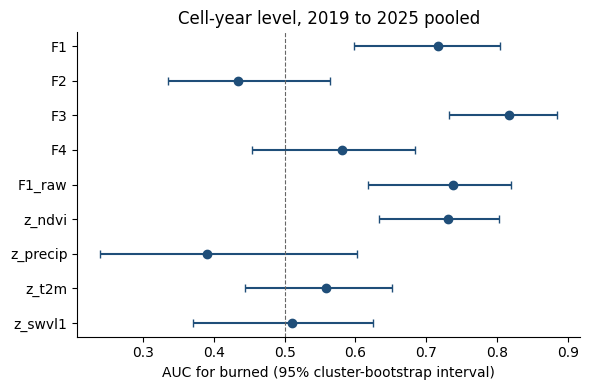

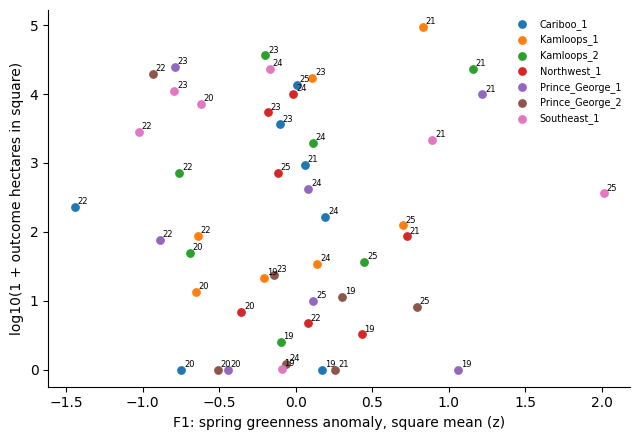

In [28]:
d = auc_tab[auc_tab.scope == "pooled"].dropna(subset=["auc"]).iloc[::-1]
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(d.auc, range(len(d)), xerr=[d.auc - d.lo, d.hi - d.auc], fmt="o", color="#1f4e79", capsize=3)
ax.set_yticks(range(len(d)), d.feature)
ax.axvline(0.5, color="0.4", lw=0.8, ls="--")
ax.set_xlabel("AUC for burned (95% cluster-bootstrap interval)")
ax.set_title(f"Cell-year level, {ANALYSIS_YEARS[0]} to {ANALYSIS_YEARS[-1]} pooled")
for s in ("top", "right"): ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(OUT_DIR / "fig_auc_forest.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for sq, g in ry.groupby("square_id"):
    ax.scatter(g.F1, g.log_ha, s=28, label=sq)
    for t in g.itertuples():
        ax.annotate(str(t.year)[2:], (t.F1, t.log_ha), fontsize=6, xytext=(2, 2), textcoords="offset points")
ax.set_xlabel("F1: spring greenness anomaly, square mean (z)")
ax.set_ylabel("log10(1 + outcome hectares in square)")
ax.legend(fontsize=7, frameon=False)
for s in ("top", "right"): ax.spines[s].set_visible(False)
fig.tight_layout(); fig.savefig(OUT_DIR / "fig_region_year_F1.png", dpi=150); plt.show()

Summary of the numbers the decision used, saved as a text file.

In [29]:
pooled = auc_tab[auc_tab.scope == "pooled"].set_index("feature")
spec2 = reg_tab[reg_tab.spec == "ii"].set_index("feature")
lines = [f"Run {datetime.now():%Y-%m-%d %H:%M}, analysis years {ANALYSIS_YEARS[0]} to {ANALYSIS_YEARS[-1]}, "
         f"{len(ana):,} cell-years kept, {int(ana.burned.sum()):,} burned, N_BOOT={N_BOOT}", ""]
for f in DECIDING_FEATURES:
    a = pooled.loc[f]
    p2 = spec2.loc[f, "p"] if f in spec2.index else np.nan
    c2 = spec2.loc[f, "coef"] if f in spec2.index else np.nan
    lines.append(f"{f}: AUC {a.auc:.3f} [{a.lo:.3f}, {a.hi:.3f}] interval {a.interval}; "
                 f"spec ii coef {c2:+.4f}, p = {p2:.4f} (rule: p < {P_MAX})")
lines += ["", "Reference features (what a tabular baseline already has):",
          pooled.loc[REFS, ["auc", "lo", "hi", "interval"]].round(3).to_string()]
text = "\n".join(lines)
print(text)
with open(OUT_DIR / "rq4_step7_readout.txt", "w") as fh:
    fh.write(text + "\n\n" + pooled.round(4).to_string() + "\n\n" + reg_tab.round(4).to_string()
             + "\n\n" + sp_tab.round(4).to_string())

Run 2026-11-23 16:51, analysis years 2019 to 2025, 361,200 cell-years kept, 4,740 burned, N_BOOT=1000

F1: AUC 0.717 [0.598, 0.804] interval above 0.5; spec ii coef +0.5874, p = 0.0000 (rule: p < 0.05)
F3: AUC 0.817 [0.732, 0.885] interval above 0.5; spec ii coef +0.9745, p = 0.0000 (rule: p < 0.05)

Reference features (what a tabular baseline already has):
           auc    lo    hi      interval
feature                                 
z_ndvi   0.731 0.634 0.803     above 0.5
z_precip  0.39 0.239 0.603  includes 0.5
z_t2m    0.558 0.444 0.652  includes 0.5
z_swvl1   0.51  0.37 0.625  includes 0.5


## Results

- Burned cells had a greener spring than usual (F1 AUC 0.717, interval above 0.5), and F1 stayed significant with NDVI and weather in the regression (p < 0.001).
- At the square level there was no link (F1 Spearman −0.08, p = 0.60). NDVI alone did about as well as F1 (0.731).
- **This is a link, not a forecast.** F1 here compares each spring with later years too, which can make the spring before a fire look greener. Test 2 (a separate notebook) compares each spring with earlier years only and tests a forecast model on unseen years.

**Planned sensitivity runs** (not run in this notebook): F1 without standardising (`F1_raw`, shown above), vegetation threshold 0.3 or 0.7, cloud threshold 0.50 or 0.65, fire season from 1 July, FIRMS as the outcome, and Level-1C images.

## 8. Rerun with features from earlier years only (requested 19 November 2026)

In sections 3 and 4, F1, F3 and the NDVI comparison compare each year with **all other years**, including years after the fire. This section rebuilds the three features so that each year is compared only with **earlier years**, the same rule used in Test 2. The cell-years, fire labels and removals are the same as in section 7 (361,200 kept cell-years, 4,740 burned).

**Earlier-years-only anomaly.** For a cell and month in year y: z = (value in year y − mean of the earlier years) / standard deviation of the earlier years. At least `MIN_PREV_YEARS` (2) earlier valid years are needed, as in Test 2.

- **F1 (new)**: mean of the April and May anomalies of year y. The Sentinel-2 record starts in 2019, so the first fire year with a value is 2021. This is the same F1 as `F1_trail_l2a` in Test 2.
- **F3 (new)**: mean of the August and September anomalies of year y − 1, where year y − 1 is compared with the years before it. The first fire year with a value is 2022.
- **NDVI (new)**: mean of the April and May MODIS NDVI anomalies of year y. The NDVI record is started in 2019, the same year as Sentinel-2, which means the only change from the old version is the set of comparison years.

For each fire year the table gives the AUC of the old and the new version. Because the new features start later and need two earlier years, fewer cells have a new value. The old AUC is therefore also given on exactly the cells that have the new value ("same cells"), which is the like-for-like comparison.

This section reads only files saved earlier in Drive. After a restart it can be run on its own: run the first code cell of the notebook (Drive and libraries), then the cells below.

In [30]:
# ---- Settings and helper functions for Section 8 ----
from pathlib import Path
import re, json, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=RuntimeWarning)

BASE_DIR   = Path("/content/drive/MyDrive")
RASTER_DIR = BASE_DIR / "rq4_s2"           # Earth Engine exports
OUT_DIR    = BASE_DIR / "rq4_outputs"      # tables saved in sections 3 to 7
RERUN_DIR  = OUT_DIR / "test1_rerun"       # results of this section
RERUN_DIR.mkdir(parents=True, exist_ok=True)

SQUARE_IDS = ["Prince_George_1", "Prince_George_2", "Kamloops_1", "Kamloops_2",
              "Cariboo_1", "Southeast_1", "Northwest_1"]
ANALYSIS_YEARS = list(range(2019, 2026))   # fire years, as in section 7
EXCLUDE = ["burned_before", "early_nbac", "early_firms", "late_nbac", "unknown_nbac", "prescribed_nbac"]
MIN_CLEAR = 2           # clear views needed for a valid month
MIN_PREV_YEARS = 2      # earlier valid years needed for an anomaly (same as Test 2)
NDVI_FIRST_YEAR = 2019  # NDVI record starts with the Sentinel-2 record
N_BOOT, BOOT_SEED = 1000, 20261014
keys = ["square_id", "year", "row", "col"]
PAIRS = [("F1", "F1_new", "F1"), ("F3", "F3_new", "F3"), ("z_ndvi", "z_ndvi_new", "NDVI")]   # (old, new, name)


def trailing_z(x, valid, min_prev):
    """Anomaly of each year against EARLIER years only. x, valid: arrays (years, 100, 100)."""
    z = np.full(x.shape, np.nan, np.float32)
    for i in range(1, x.shape[0]):                     # year 0 has no earlier years
        prev = np.where(valid[:i], x[:i], np.nan)      # earlier years, invalid months removed
        n, mu, sd = np.isfinite(prev).sum(0), np.nanmean(prev, 0), np.nanstd(prev, 0, ddof=1)
        ok = valid[i] & (n >= min_prev) & (sd > 0)
        z[i] = np.where(ok, (x[i] - mu) / sd, np.nan)
    return z


def both_mean(a, b):
    """Mean of two months, only where both have a value."""
    return np.where(np.isfinite(a) & np.isfinite(b), (a + b) / 2.0, np.nan)


def cluster_bootstrap_auc(y, score, cluster):
    """AUC, with a 95% interval from resampling whole square-years (same method as section 7).
    Resampling a square-year k times is the same as giving its cells weight k, which keeps this fast."""
    ok = np.isfinite(score)
    y, score, cluster = np.asarray(y, float)[ok], np.asarray(score, float)[ok], np.asarray(cluster)[ok]
    n, n_burned = len(y), int(y.sum())
    if n == 0 or n_burned in (0, n):
        return dict(auc=np.nan, lo=np.nan, hi=np.nan, n=n, n_burned=n_burned)

    order = np.argsort(score, kind="mergesort")              # sort cells by score once
    y = y[order]
    rank = np.concatenate([[0], np.cumsum(np.diff(score[order]) != 0)])   # equal scores share a rank
    ids, sq_of_cell = np.unique(cluster[order], return_inverse=True)

    def auc(w):
        # weighted AUC: share of (burned, unburned) pairs where the burned cell scores higher, ties count 1/2
        pos = np.bincount(rank, weights=w * y)              # weighted burned cells at each rank
        neg = np.bincount(rank, weights=w * (1 - y))        # weighted unburned cells at each rank
        below = np.cumsum(neg) - neg                        # unburned cells with a lower score
        denom = pos.sum() * neg.sum()
        return np.nan if denom == 0 else float((pos * (below + 0.5 * neg)).sum() / denom)

    rng = np.random.default_rng(BOOT_SEED)
    boots = []
    for _ in range(N_BOOT):
        times_drawn = np.bincount(rng.integers(0, len(ids), len(ids)), minlength=len(ids))
        a = auc(times_drawn[sq_of_cell].astype(float))
        if np.isfinite(a):
            boots.append(a)
    lo, hi = np.percentile(boots, [2.5, 97.5]) if boots else (np.nan, np.nan)
    return dict(auc=auc(np.ones(n)), lo=lo, hi=hi, n=n, n_burned=n_burned)


print("Section 8 settings ready. Results go to", RERUN_DIR)

Section 8 settings ready. Results go to /content/drive/MyDrive/rq4_outputs/test1_rerun


Rebuild the same kept cell-years as section 7 and check the counts against the 17 October run.

In [31]:
# ---- Same kept cell-years as section 7 ----
feat = pd.read_parquet(OUT_DIR / "rq4_cell_year_features.parquet", columns=keys + ["veg_ok", "F1", "F3"])
refs = pd.read_parquet(OUT_DIR / "rq4_cell_year_reference.parquet", columns=keys + ["z_ndvi"])
outc = pd.read_parquet(OUT_DIR / "rq4_cell_year_outcomes.parquet",
                       columns=keys + ["burned", "nbac_year_available"] + EXCLUDE)
for t in (feat, refs, outc):
    t["square_id"] = t["square_id"].astype(str)

t = feat.merge(refs, on=keys, how="left").merge(outc, on=keys, how="inner")
t = t[t.year.isin(ANALYSIS_YEARS) & t.nbac_year_available]
kept = t[t.veg_ok & ~t[EXCLUDE].any(axis=1)].copy()          # same removals as section 7
kept["burned"] = kept["burned"].astype(bool)
kept["square_year"] = kept.square_id + "_" + kept.year.astype(str)   # cluster for the bootstrap
print(f"{len(kept):,} kept cell-years, {int(kept.burned.sum()):,} burned (17 October run: 361,200 and 4,740)")

361,200 kept cell-years, 4,740 burned (17 October run: 361,200 and 4,740)


Build the new F1 and F3 from the monthly greenness saved in section 3 (`rq4_cell_month.parquet`). A month is valid with at least two clear views, as before.

In [32]:
# ---- New F1 (April, May of year y) and new F3 (August, September of year y-1) ----
cm = pd.read_parquet(OUT_DIR / "rq4_cell_month.parquet",
                     columns=["square_id", "year", "month", "row", "col", "gcc", "n_clear"],
                     filters=[("month", "in", [4, 5, 8, 9])])
cm["square_id"] = cm["square_id"].astype(str)
s2_years = sorted(cm.year.unique())
print("Sentinel-2 years in the file:", [int(y) for y in s2_years])

rr, cc = np.meshgrid(np.arange(100), np.arange(100), indexing="ij")   # row and column of every cell
frames = []
for sq in SQUARE_IDS:
    z = {}
    for m in (4, 5, 8, 9):
        c = cm[(cm.square_id == sq) & (cm.month == m)]
        yi = c.year.map({y: i for i, y in enumerate(s2_years)}).values
        x = np.full((len(s2_years), 100, 100), np.nan, np.float32)    # greenness, one map per year
        v = np.zeros((len(s2_years), 100, 100), bool)                 # valid month (2+ clear views)
        x[yi, c.row.values, c.col.values] = c.gcc.values
        v[yi, c.row.values, c.col.values] = (c.n_clear.values >= MIN_CLEAR) & np.isfinite(c.gcc.values)
        z[m] = trailing_z(x, v, MIN_PREV_YEARS)
    for i, y in enumerate(s2_years):
        f1 = both_mean(z[4][i], z[5][i])
        f3 = both_mean(z[8][i - 1], z[9][i - 1]) if i > 0 else np.full((100, 100), np.nan)
        frames.append(pd.DataFrame({"square_id": sq, "year": y, "row": rr.ravel(), "col": cc.ravel(),
                                    "F1_new": f1.ravel(), "F3_new": f3.ravel()}))
s2_new = pd.concat(frames, ignore_index=True)

# Check: the new F1 should be the same as the F1 used in Test 2
t2_path = OUT_DIR / "followup" / "followup_analysis_table.parquet"
if t2_path.exists():
    chk = pd.read_parquet(t2_path, columns=keys + ["F1_trail_l2a"]).astype({"square_id": str}).merge(s2_new, on=keys)
    both = chk.F1_trail_l2a.notna() & chk.F1_new.notna()
    print(f"Check against Test 2: {int(both.sum()):,} cells compared, largest difference "
          f"{float((chk.F1_trail_l2a - chk.F1_new)[both].abs().max()):.2e}, "
          f"cells with a value in only one of the two: {int((chk.F1_trail_l2a.notna() != chk.F1_new.notna()).sum())}")
else:
    print("Test 2 table not found, check against Test 2 skipped")

Sentinel-2 years in the file: [2019, 2020, 2021, 2022, 2023, 2024, 2025, 2026]
Check against Test 2: 213,432 cells compared, largest difference 0.00e+00, cells with a value in only one of the two: 0


Build the new NDVI comparison from the monthly MODIS NDVI files (`rq4_ndvi_<square>.tif`, bands `ndvi_YYYY_MM`). A month is valid where it has a value, as in section 4.

In [33]:
# ---- New NDVI (April, May of year y) from the MODIS files ----
nd_years = list(range(NDVI_FIRST_YEAR, max(ANALYSIS_YEARS) + 1))
frames = []
for sq in SQUARE_IDS:
    x = {m: np.full((len(nd_years), 100, 100), np.nan, np.float32) for m in (4, 5)}
    with rasterio.open(RASTER_DIR / f"rq4_ndvi_{sq}.tif") as r:
        if r.crs.to_epsg() != 3005 or (r.width, r.height) != (100, 100):
            raise ValueError(f"rq4_ndvi_{sq}.tif is not on the 1 km grid")
        for b, name in enumerate(r.descriptions, start=1):        # band names look like ndvi_2023_05
            m = re.match(r"^ndvi_(\d{4})_(\d{2})$", name or "")
            if m and int(m.group(1)) in nd_years and int(m.group(2)) in (4, 5):
                a = r.read(b).astype(np.float32)
                if r.nodata is not None:
                    a[a == r.nodata] = np.nan
                x[int(m.group(2))][nd_years.index(int(m.group(1)))] = a
    nd = both_mean(trailing_z(x[4], np.isfinite(x[4]), MIN_PREV_YEARS),
                   trailing_z(x[5], np.isfinite(x[5]), MIN_PREV_YEARS))
    for i, y in enumerate(nd_years):
        frames.append(pd.DataFrame({"square_id": sq, "year": y, "row": rr.ravel(), "col": cc.ravel(),
                                    "z_ndvi_new": nd[i].ravel()}))
ndvi_new = pd.concat(frames, ignore_index=True)

# Add the new features to the kept cell-years and save the table
ana8 = kept.merge(s2_new, on=keys, how="left").merge(ndvi_new, on=keys, how="left")
ana8[keys + ["burned", "F1", "F1_new", "F3", "F3_new", "z_ndvi", "z_ndvi_new"]].to_parquet(
    RERUN_DIR / "test1_rerun_table.parquet", index=False)

print("Kept cell-years with a value, old and new version, by fire year:")
ana8.groupby("year")[["F1", "F1_new", "F3", "F3_new", "z_ndvi", "z_ndvi_new"]].count()

Kept cell-years with a value, old and new version, by fire year:


,F1,F1_new,F3,F3_new,z_ndvi,z_ndvi_new
year,,,,,,
2019,49662,0,0,0,43102,0
2020,48478,0,49161,0,40390,0
2021,47944,43211,45486,0,40009,37628
2022,38980,38994,38075,32481,36156,35681
2023,45512,46097,49660,47643,39692,38952
2024,40741,40796,48216,48059,39647,40291
2025,43957,44334,46017,46117,39269,41351


AUC of the old and the new version of each feature, for each fire year and pooled over the years where the new version exists. The 95% intervals come from the same cluster bootstrap as section 7 (square-years drawn with replacement). Within one fire year there are only seven squares, which makes the yearly intervals wide.

- `auc_old`: old version, all kept cells with an old value (the section 7 numbers).
- `auc_old_same`: old version, only the cells that also have a new value.
- `auc_new`: new version.
- `change` = `auc_new` − `auc_old_same`.

In [34]:
# ---- AUC of old and new versions, per fire year and pooled ----
rows = []
for old, new, name in PAIRS:
    new_years = sorted(ana8.loc[ana8[new].notna(), "year"].unique())          # years with a new value
    scopes = [(str(y), ana8[ana8.year == y]) for y in ANALYSIS_YEARS]
    scopes.append((f"pooled {new_years[0]}-{new_years[-1]}", ana8[ana8.year.isin(new_years)]))
    for scope, d in scopes:
        same = d[d[old].notna() & d[new].notna()]                             # cells with both versions
        a_old  = cluster_bootstrap_auc(d.burned, d[old], d.square_year)       # old, all cells
        a_same = cluster_bootstrap_auc(same.burned, same[old], same.square_year)   # old, same cells
        a_new  = cluster_bootstrap_auc(same.burned, same[new], same.square_year)   # new
        rows.append({"feature": name, "fire_year": scope,
                     "n_old": a_old["n"], "burned_old": a_old["n_burned"],
                     "auc_old": a_old["auc"], "lo_old": a_old["lo"], "hi_old": a_old["hi"],
                     "n_new": a_new["n"], "burned_new": a_new["n_burned"],
                     "auc_old_same": a_same["auc"], "lo_old_same": a_same["lo"], "hi_old_same": a_same["hi"],
                     "auc_new": a_new["auc"], "lo_new": a_new["lo"], "hi_new": a_new["hi"],
                     "change": a_new["auc"] - a_same["auc"]})
rerun = pd.DataFrame(rows)
rerun.to_csv(RERUN_DIR / "test1_rerun_auc.csv", index=False)

# Check: the old yearly AUC should match section 7
s7 = pd.read_csv(OUT_DIR / "rq4_step7_auc.csv")
s7 = s7[s7.scope.astype(str).isin([str(y) for y in ANALYSIS_YEARS])]
s7 = s7.assign(feature=s7.feature.replace({"z_ndvi": "NDVI"}), fire_year=s7.scope.astype(str))
chk = rerun.merge(s7[["feature", "fire_year", "auc"]], on=["feature", "fire_year"])
print("Largest difference from the section 7 yearly AUC:", f"{float((chk.auc_old - chk.auc).abs().max()):.2e}")

rerun[["feature", "fire_year", "n_old", "burned_old", "auc_old",
       "n_new", "burned_new", "auc_old_same", "auc_new", "change"]].round(3)

Largest difference from the section 7 yearly AUC: 0.00e+00


,feature,fire_year,n_old,burned_old,auc_old,n_new,burned_new,auc_old_same,auc_new,change
0,F1,2019,49662,12,0.466,0,0,NaN,NaN,NaN
1,F1,2020,48478,93,0.83,0,0,NaN,NaN,NaN
2,F1,2021,47944,1470,0.837,43174,1122,0.829,0.655,-0.174
3,F1,2022,38980,314,0.744,38875,314,0.744,0.426,-0.319
4,F1,2023,45512,1447,0.696,45436,1436,0.698,0.442,-0.256
5,F1,2024,40741,371,0.714,40741,371,0.714,0.555,-0.158
6,F1,2025,43957,247,0.396,43957,247,0.396,0.287,-0.109
7,F1,pooled 2021-2025,217134,3849,0.696,212183,3490,0.678,0.534,-0.144
8,F3,2019,0,0,NaN,0,0,NaN,NaN,NaN
9,F3,2020,49161,114,0.928,0,0,NaN,NaN,NaN


The same results as a figure: old version (same cells) and new version per fire year, one panel per feature.

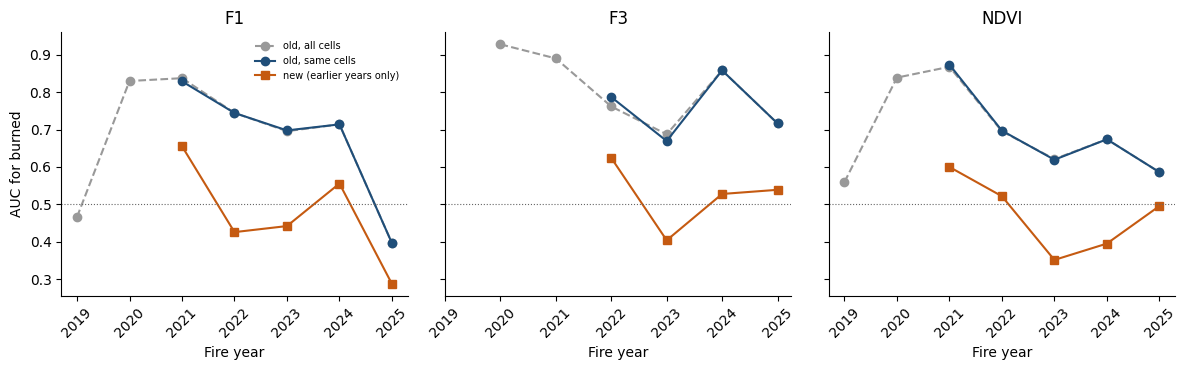

In [35]:
# ---- Figure: AUC by fire year, one panel per feature ----
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, (old, new, name) in zip(axes, PAIRS):
    d = rerun[(rerun.feature == name) & rerun.fire_year.isin([str(y) for y in ANALYSIS_YEARS])]
    x = d.fire_year.astype(int)
    ax.plot(x, d.auc_old, "o--", color="0.6", label="old, all cells")
    ax.plot(x, d.auc_old_same, "o-", color="#1f4e79", label="old, same cells")
    ax.plot(x, d.auc_new, "s-", color="#c55a11", label="new (earlier years only)")
    ax.axhline(0.5, color="0.4", lw=0.8, ls=":")                  # 0.5 = no link
    ax.set_title(name); ax.set_xlabel("Fire year"); ax.set_xticks(list(ANALYSIS_YEARS))
    ax.tick_params(axis="x", labelrotation=45)
    for s in ("top", "right"): ax.spines[s].set_visible(False)
axes[0].set_ylabel("AUC for burned")
axes[0].legend(fontsize=7, frameon=False)
fig.tight_layout(); fig.savefig(RERUN_DIR / "fig_test1_rerun_auc.png", dpi=150); plt.show()

Pooled results with their intervals, saved as a text file with the run settings.

In [36]:
# ---- Pooled results as text, saved with the settings ----
pooled = rerun[rerun.fire_year.str.startswith("pooled")]
lines = [f"Test 1 rerun, {datetime.now():%Y-%m-%d %H:%M}. Earlier-years-only anomalies, "
         f"MIN_PREV_YEARS = {MIN_PREV_YEARS}, NDVI from {NDVI_FIRST_YEAR}, N_BOOT = {N_BOOT}.",
         f"Kept cell-years: {len(ana8):,}, burned: {int(ana8.burned.sum()):,}", ""]
for r in pooled.itertuples():
    lines.append(f"{r.feature}, {r.fire_year}: {r.n_new:,} cell-years ({r.burned_new:,} burned). "
                 f"Old {r.auc_old_same:.3f} [{r.lo_old_same:.3f}, {r.hi_old_same:.3f}], "
                 f"new {r.auc_new:.3f} [{r.lo_new:.3f}, {r.hi_new:.3f}], change {r.change:+.3f}")
text = "\n".join(lines)
print(text)
with open(RERUN_DIR / "test1_rerun_readout.txt", "w") as fh:
    fh.write(text + "\n\n" + rerun.round(4).to_string())
with open(RERUN_DIR / "test1_rerun_settings.json", "w") as fh:
    json.dump({"run_at": datetime.now().isoformat(timespec="seconds"), "MIN_PREV_YEARS": MIN_PREV_YEARS,
               "MIN_CLEAR": MIN_CLEAR, "NDVI_FIRST_YEAR": NDVI_FIRST_YEAR, "N_BOOT": N_BOOT,
               "BOOT_SEED": BOOT_SEED, "ANALYSIS_YEARS": ANALYSIS_YEARS}, fh, indent=2)

Test 1 rerun, 2026-11-23 16:53. Earlier-years-only anomalies, MIN_PREV_YEARS = 2, NDVI from 2019, N_BOOT = 1000.
Kept cell-years: 361,200, burned: 4,740

F1, pooled 2021-2025: 212,183 cell-years (3,490 burned). Old 0.678 [0.572, 0.773], new 0.534 [0.387, 0.679], change -0.144
F3, pooled 2022-2025: 174,168 cell-years (2,623 burned). Old 0.764 [0.692, 0.819], new 0.563 [0.465, 0.646], change -0.201
NDVI, pooled 2021-2025: 190,889 cell-years (3,673 burned). Old 0.738 [0.631, 0.817], new 0.493 [0.390, 0.572], change -0.244
